### imports

In [1]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold)


from scipy.signal import convolve, windows
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from pyglmnet import GLM


import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d
from sklearn.pipeline import make_pipeline
from scipy.stats import mannwhitneyu


In [ ]:
from functions_experimental_data_Bräckleinexp.GLM_analysis_spikes_pred import *
from functions_experimental_data_Bräckleinexp.GLM_analysis_force_pred import *
from functions_experimental_data_Bräckleinexp.create_rasters import *
from functions_experimental_data_Bräckleinexp.force_trajectories import *
from functions_experimental_data_Bräckleinexp.count_peaks_smoothnes import *
from functions_experimental_data_Bräckleinexp.firing_rates import *

## Load all sessions

In [3]:
session_files1 = {
    "Day01": [
        'E3_MB01_Day01High_1.pkl', 'E3_MB01_Day01High_11.pkl', 'E3_MB01_Day01High_14.pkl',
        'E3_MB01_Day01High_17.pkl', 'E3_MB01_Day01High_21.pkl', 'E3_MB01_Day01High_24.pkl',
        'E3_MB01_Day01High_27.pkl', 'E3_MB01_Day01High_30.pkl', 'E3_MB01_Day01High_6.pkl',
        'E3_MB01_Day01High_9.pkl'
    ],
    "Day03": [
        'E3_MB01_Day03High_11.pkl', 'E3_MB01_Day03High_14.pkl', 'E3_MB01_Day03High_18.pkl',
        'E3_MB01_Day03High_21.pkl', 'E3_MB01_Day03High_23.pkl', 'E3_MB01_Day03High_26.pkl',
        'E3_MB01_Day03High_29.pkl', 'E3_MB01_Day03High_3.pkl', 'E3_MB01_Day03High_4.pkl',
        'E3_MB01_Day03High_9.pkl'
    ],
    "Day04": [
        'E3_MB01_Day04High_1.pkl', 'E3_MB01_Day04High_10.pkl', 'E3_MB01_Day04High_13.pkl',
        'E3_MB01_Day04High_17.pkl', 'E3_MB01_Day04High_20.pkl', 'E3_MB01_Day04High_23.pkl',
        'E3_MB01_Day04High_25.pkl', 'E3_MB01_Day04High_29.pkl', 'E3_MB01_Day04High_30.pkl',
        'E3_MB01_Day04High_6.pkl', 'E3_MB01_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB01_Day05High_1.pkl', 'E3_MB01_Day05High_10.pkl', 'E3_MB01_Day05High_13.pkl',
        'E3_MB01_Day05High_18.pkl', 'E3_MB01_Day05High_21.pkl', 'E3_MB01_Day05High_23.pkl',
        'E3_MB01_Day05High_26.pkl', 'E3_MB01_Day05High_28.pkl', 'E3_MB01_Day05High_5.pkl',
        'E3_MB01_Day05High_9.pkl'
    ],
    "Day06": [
        'E3_MB01_Day06High_10.pkl', 'E3_MB01_Day06High_14.pkl', 'E3_MB01_Day06High_18.pkl',
        'E3_MB01_Day06High_21.pkl', 'E3_MB01_Day06High_22.pkl', 'E3_MB01_Day06High_26.pkl',
        'E3_MB01_Day06High_3.pkl', 'E3_MB01_Day06High_30.pkl', 'E3_MB01_Day06High_5.pkl',
        'E3_MB01_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB01_Day07High_1.pkl', 'E3_MB01_Day07High_10.pkl', 'E3_MB01_Day07High_14.pkl',
        'E3_MB01_Day07High_18.pkl', 'E3_MB01_Day07High_19.pkl', 'E3_MB01_Day07High_23.pkl',
        'E3_MB01_Day07High_26.pkl', 'E3_MB01_Day07High_28.pkl', 'E3_MB01_Day07High_5.pkl',
        'E3_MB01_Day07High_9.pkl'
        
    ],
    
    "Day08": ['E3_MB01_Day08High_12.pkl', 'E3_MB01_Day08High_13.pkl', 'E3_MB01_Day08High_17.pkl',
              'E3_MB01_Day08High_21.pkl', 'E3_MB01_Day08High_23.pkl', 'E3_MB01_Day08High_25.pkl',
              'E3_MB01_Day08High_3.pkl', 'E3_MB01_Day08High_30.pkl', 'E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl', 'E3_MB01_Day09High_13.pkl', 'E3_MB01_Day09High_15.pkl',
              'E3_MB01_Day09High_18.pkl', 'E3_MB01_Day09High_23.pkl', 'E3_MB01_Day09High_26.pkl',
              'E3_MB01_Day09High_27.pkl', 'E3_MB01_Day09High_4.pkl', 'E3_MB01_Day09High_8.pkl',
              'E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl', 'E3_MB01_Day10High_10.pkl', 'E3_MB01_Day10High_15.pkl',
              'E3_MB01_Day10High_18.pkl', 'E3_MB01_Day10High_19.pkl', 'E3_MB01_Day10High_22.pkl',
              'E3_MB01_Day10High_25.pkl', 'E3_MB01_Day10High_30.pkl', 'E3_MB01_Day10High_5.pkl',
              'E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl', 'E3_MB01_Day11High_15.pkl', 'E3_MB01_Day11High_18.pkl',
              'E3_MB01_Day11High_20.pkl', 'E3_MB01_Day11High_24.pkl', 'E3_MB01_Day11High_25.pkl',
              'E3_MB01_Day11High_28.pkl', 'E3_MB01_Day11High_3.pkl', 'E3_MB01_Day11High_4.pkl',
              'E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl', 'E3_MB01_Day12High_15.pkl', 'E3_MB01_Day12High_17.pkl',
              'E3_MB01_Day12High_2.pkl', 'E3_MB01_Day12High_20.pkl', 'E3_MB01_Day12High_24.pkl',
              'E3_MB01_Day12High_25.pkl', 'E3_MB01_Day12High_28.pkl', 'E3_MB01_Day12High_4.pkl',
              'E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl', 'E3_MB01_Day13High_12.pkl', 'E3_MB01_Day13High_14.pkl',
              'E3_MB01_Day13High_16.pkl', 'E3_MB01_Day13High_19.pkl', 'E3_MB01_Day13High_23.pkl',
              'E3_MB01_Day13High_25.pkl', 'E3_MB01_Day13High_30.pkl', 'E3_MB01_Day13High_5.pkl',
              'E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl', 'E3_MB01_Day14High_15.pkl', 'E3_MB01_Day14High_18.pkl',
              'E3_MB01_Day14High_19.pkl', 'E3_MB01_Day14High_22.pkl', 'E3_MB01_Day14High_26.pkl',
              'E3_MB01_Day14High_28.pkl', 'E3_MB01_Day14High_3.pkl', 'E3_MB01_Day14High_5.pkl',
              'E3_MB01_Day14High_8.pkl']

}



#######################





session_files3 = {
    "Day01": ['E3_MB03_Day01High_12.pkl', 'E3_MB03_Day01High_14.pkl', 'E3_MB03_Day01High_16.pkl',
              'E3_MB03_Day01High_19.pkl', 'E3_MB03_Day01High_23.pkl', 'E3_MB03_Day01High_27.pkl',
              'E3_MB03_Day01High_29.pkl', 'E3_MB03_Day01High_3.pkl', 'E3_MB03_Day01High_4.pkl',
              'E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl', 'E3_MB03_Day02High_15.pkl', 'E3_MB03_Day02High_17.pkl',
              'E3_MB03_Day02High_19.pkl', 'E3_MB03_Day02High_2.pkl', 'E3_MB03_Day02High_24.pkl',
              'E3_MB03_Day02High_26.pkl', 'E3_MB03_Day02High_29.pkl', 'E3_MB03_Day02High_6.pkl',
              'E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl', 'E3_MB03_Day03High_15.pkl', 'E3_MB03_Day03High_17.pkl',
              'E3_MB03_Day03High_2.pkl', 'E3_MB03_Day03High_21.pkl', 'E3_MB03_Day03High_23.pkl',
              'E3_MB03_Day03High_26.pkl', 'E3_MB03_Day03High_29.pkl', 'E3_MB03_Day03High_5.pkl',
              'E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl', 'E3_MB03_Day04High_11.pkl', 'E3_MB03_Day04High_15.pkl',
              'E3_MB03_Day04High_16.pkl', 'E3_MB03_Day04High_20.pkl', 'E3_MB03_Day04High_23.pkl',
              'E3_MB03_Day04High_26.pkl', 'E3_MB03_Day04High_28.pkl', 'E3_MB03_Day04High_4.pkl',
              'E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl', 'E3_MB03_Day05High_15.pkl', 'E3_MB03_Day05High_17.pkl',
              'E3_MB03_Day05High_20.pkl', 'E3_MB03_Day05High_22.pkl', 'E3_MB03_Day05High_26.pkl',
              'E3_MB03_Day05High_29.pkl', 'E3_MB03_Day05High_3.pkl', 'E3_MB03_Day05High_4.pkl',
              'E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl', 'E3_MB03_Day07High_13.pkl', 'E3_MB03_Day07High_18.pkl',
              'E3_MB03_Day07High_19.pkl', 'E3_MB03_Day07High_22.pkl', 'E3_MB03_Day07High_27.pkl',
              'E3_MB03_Day07High_29.pkl', 'E3_MB03_Day07High_3.pkl', 'E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl', 'E3_MB03_Day10High_13.pkl', 'E3_MB03_Day10High_17.pkl',
              'E3_MB03_Day10High_21.pkl', 'E3_MB03_Day10High_22.pkl', 'E3_MB03_Day10High_25.pkl',
              'E3_MB03_Day10High_3.pkl', 'E3_MB03_Day10High_30.pkl', 'E3_MB03_Day10High_5.pkl',
              'E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl', 'E3_MB03_Day11High_14.pkl', 'E3_MB03_Day11High_18.pkl',
              'E3_MB03_Day11High_20.pkl', 'E3_MB03_Day11High_23.pkl', 'E3_MB03_Day11High_26.pkl',
              'E3_MB03_Day11High_3.pkl', 'E3_MB03_Day11High_30.pkl', 'E3_MB03_Day11High_6.pkl',
              'E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl', 'E3_MB03_Day12High_13.pkl', 'E3_MB03_Day12High_17.pkl',
              'E3_MB03_Day12High_21.pkl', 'E3_MB03_Day12High_22.pkl', 'E3_MB03_Day12High_25.pkl',
              'E3_MB03_Day12High_29.pkl', 'E3_MB03_Day12High_3.pkl', 'E3_MB03_Day12High_5.pkl',
              'E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl', 'E3_MB03_Day13High_13.pkl', 'E3_MB03_Day13High_18.pkl',
              'E3_MB03_Day13High_19.pkl', 'E3_MB03_Day13High_2.pkl', 'E3_MB03_Day13High_24.pkl',
              'E3_MB03_Day13High_27.pkl', 'E3_MB03_Day13High_29.pkl', 'E3_MB03_Day13High_5.pkl',
              'E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl', 'E3_MB03_Day14High_13.pkl', 'E3_MB03_Day14High_16.pkl',
              'E3_MB03_Day14High_21.pkl', 'E3_MB03_Day14High_24.pkl', 'E3_MB03_Day14High_26.pkl',
              'E3_MB03_Day14High_29.pkl', 'E3_MB03_Day14High_3.pkl', 'E3_MB03_Day14High_4.pkl',
              'E3_MB03_Day14High_8.pkl']
}


#######################



session_files2 = {
    "Day02": [
        'E3_MB02_Day02High_10.pkl', 'E3_MB02_Day02High_14.pkl', 'E3_MB02_Day02High_18.pkl',
        'E3_MB02_Day02High_2.pkl', 'E3_MB02_Day02High_20.pkl', 'E3_MB02_Day02High_24.pkl',
        'E3_MB02_Day02High_27.pkl', 'E3_MB02_Day02High_29.pkl', 'E3_MB02_Day02High_6.pkl',
        'E3_MB02_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB02_Day03High_11.pkl', 'E3_MB02_Day03High_13.pkl', 'E3_MB02_Day03High_18.pkl',
        'E3_MB02_Day03High_21.pkl', 'E3_MB02_Day03High_24.pkl', 'E3_MB02_Day03High_26.pkl',
        'E3_MB02_Day03High_29.pkl', 'E3_MB02_Day03High_3.pkl', 'E3_MB02_Day03High_5.pkl',
        'E3_MB02_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB02_Day04High_11.pkl', 'E3_MB02_Day04High_14.pkl', 'E3_MB02_Day04High_16.pkl',
        'E3_MB02_Day04High_2.pkl', 'E3_MB02_Day04High_21.pkl', 'E3_MB02_Day04High_22.pkl',
        'E3_MB02_Day04High_27.pkl', 'E3_MB02_Day04High_30.pkl', 'E3_MB02_Day04High_5.pkl',
        'E3_MB02_Day04High_7.pkl'
    ],
    "Day07": [
        'E3_MB02_Day07High_1.pkl', 'E3_MB02_Day07High_12.pkl', 'E3_MB02_Day07High_13.pkl',
        'E3_MB02_Day07High_16.pkl', 'E3_MB02_Day07High_19.pkl', 'E3_MB02_Day07High_24.pkl',
        'E3_MB02_Day07High_27.pkl', 'E3_MB02_Day07High_30.pkl', 'E3_MB02_Day07High_4.pkl',
        'E3_MB02_Day07High_9.pkl'
    ],
    "Day13": [
        'E3_MB02_Day13High_1.pkl', 'E3_MB02_Day13High_11.pkl', 'E3_MB02_Day13High_13.pkl',
        'E3_MB02_Day13High_18.pkl', 'E3_MB02_Day13High_20.pkl', 'E3_MB02_Day13High_23.pkl',
        'E3_MB02_Day13High_26.pkl', 'E3_MB02_Day13High_28.pkl', 'E3_MB02_Day13High_4.pkl',
        'E3_MB02_Day13High_8.pkl'
    ]
}



#######################




session_files4 = {
    "Day01": ['E3_MB04_Day01High_16.pkl', 'E3_MB04_Day01High_19.pkl', 'E3_MB04_Day01High_2.pkl',
              'E3_MB04_Day01High_24.pkl', 'E3_MB04_Day01High_26.pkl', 'E3_MB04_Day01High_30.pkl',
              'E3_MB04_Day01High_6.pkl', 'E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl', 'E3_MB04_Day03High_14.pkl', 'E3_MB04_Day03High_17.pkl',
              'E3_MB04_Day03High_19.pkl', 'E3_MB04_Day03High_22.pkl', 'E3_MB04_Day03High_27.pkl',
              'E3_MB04_Day03High_28.pkl', 'E3_MB04_Day03High_3.pkl', 'E3_MB04_Day03High_5.pkl',
              'E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl', 'E3_MB04_Day07High_29.pkl', 'E3_MB04_Day07High_6.pkl',
              'E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl', 'E3_MB04_Day08High_13.pkl', 'E3_MB04_Day08High_18.pkl',
              'E3_MB04_Day08High_19.pkl', 'E3_MB04_Day08High_2.pkl', 'E3_MB04_Day08High_22.pkl',
              'E3_MB04_Day08High_27.pkl', 'E3_MB04_Day08High_28.pkl', 'E3_MB04_Day08High_6.pkl',
              'E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl', 'E3_MB04_Day09High_19.pkl', 'E3_MB04_Day09High_24.pkl',
              'E3_MB04_Day09High_27.pkl', 'E3_MB04_Day09High_30.pkl', 'E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl', 'E3_MB04_Day10High_15.pkl', 'E3_MB04_Day10High_17.pkl',
              'E3_MB04_Day10High_2.pkl', 'E3_MB04_Day10High_21.pkl', 'E3_MB04_Day10High_22.pkl',
              'E3_MB04_Day10High_26.pkl', 'E3_MB04_Day10High_28.pkl', 'E3_MB04_Day10High_4.pkl',
              'E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl', 'E3_MB04_Day11High_14.pkl', 'E3_MB04_Day11High_16.pkl',
              'E3_MB04_Day11High_2.pkl', 'E3_MB04_Day11High_21.pkl', 'E3_MB04_Day11High_23.pkl',
              'E3_MB04_Day11High_27.pkl', 'E3_MB04_Day11High_28.pkl', 'E3_MB04_Day11High_4.pkl',
              'E3_MB04_Day11High_9.pkl'],
    
    "Day12": ['E3_MB04_Day12High_2.pkl', 'E3_MB04_Day12High_5.pkl', 'E3_MB04_Day12High_9.pkl',
              'E3_MB04_Day12High_12.pkl', 'E3_MB04_Day12High_14.pkl', 'E3_MB04_Day12High_18.pkl',
              'E3_MB04_Day12High_19.pkl', 'E3_MB04_Day12High_23.pkl', 'E3_MB04_Day12High_26.pkl',
              'E3_MB04_Day12High_29.pkl'],
        
    "Day13": ['E3_MB04_Day13High_3.pkl', 'E3_MB04_Day13High_4.pkl', 'E3_MB04_Day13High_8.pkl',
              'E3_MB04_Day13High_12.pkl', 'E3_MB04_Day13High_14.pkl', 'E3_MB04_Day13High_18.pkl',
              'E3_MB04_Day13High_19.pkl', 'E3_MB04_Day13High_24.pkl', 'E3_MB04_Day13High_27.pkl',
              'E3_MB04_Day13High_30.pkl'],
            
    "Day14": ['E3_MB04_Day14High_3.pkl', 'E3_MB04_Day14High_4.pkl', 'E3_MB04_Day14High_8.pkl',
              'E3_MB04_Day14High_11.pkl', 'E3_MB04_Day14High_13.pkl', 'E3_MB04_Day14High_18.pkl',
              'E3_MB04_Day14High_21.pkl', 'E3_MB04_Day14High_25.pkl', 'E3_MB04_Day14High_28.pkl']
}



#######################



session_files7 = {
    "Day01": [
        'E3_MB07_Day01High_10.pkl', 'E3_MB07_Day01High_13.pkl', 'E3_MB07_Day01High_17.pkl',
        'E3_MB07_Day01High_2.pkl', 'E3_MB07_Day01High_21.pkl', 'E3_MB07_Day01High_24.pkl',
        'E3_MB07_Day01High_26.pkl', 'E3_MB07_Day01High_28.pkl', 'E3_MB07_Day01High_5.pkl',
        'E3_MB07_Day01High_9.pkl'
    ],
    "Day02": [
        'E3_MB07_Day02High_10.pkl', 'E3_MB07_Day02High_15.pkl', 'E3_MB07_Day02High_17.pkl',
        'E3_MB07_Day02High_19.pkl', 'E3_MB07_Day02High_23.pkl', 'E3_MB07_Day02High_27.pkl',
        'E3_MB07_Day02High_3.pkl', 'E3_MB07_Day02High_30.pkl', 'E3_MB07_Day02High_5.pkl',
        'E3_MB07_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB07_Day03High_1.pkl', 'E3_MB07_Day03High_10.pkl', 'E3_MB07_Day03High_15.pkl',
        'E3_MB07_Day03High_18.pkl', 'E3_MB07_Day03High_19.pkl', 'E3_MB07_Day03High_22.pkl',
        'E3_MB07_Day03High_25.pkl', 'E3_MB07_Day03High_30.pkl', 'E3_MB07_Day03High_5.pkl',
        'E3_MB07_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB07_Day04High_11.pkl', 'E3_MB07_Day04High_15.pkl', 'E3_MB07_Day04High_18.pkl',
        'E3_MB07_Day04High_21.pkl', 'E3_MB07_Day04High_23.pkl', 'E3_MB07_Day04High_27.pkl',
        'E3_MB07_Day04High_28.pkl', 'E3_MB07_Day04High_3.pkl', 'E3_MB07_Day04High_6.pkl',
        'E3_MB07_Day04High_7.pkl'
    ],
    "Day05": [
        'E3_MB07_Day05High_12.pkl', 'E3_MB07_Day05High_15.pkl', 'E3_MB07_Day05High_16.pkl',
        'E3_MB07_Day05High_19.pkl', 'E3_MB07_Day05High_24.pkl', 'E3_MB07_Day05High_26.pkl',
        'E3_MB07_Day05High_3.pkl', 'E3_MB07_Day05High_30.pkl', 'E3_MB07_Day05High_5.pkl',
        'E3_MB07_Day05High_7.pkl'
    ],
    "Day06": [
        'E3_MB07_Day06High_10.pkl', 'E3_MB07_Day06High_15.pkl', 'E3_MB07_Day06High_16.pkl',
        'E3_MB07_Day06High_19.pkl', 'E3_MB07_Day06High_24.pkl', 'E3_MB07_Day06High_25.pkl',
        'E3_MB07_Day06High_29.pkl', 'E3_MB07_Day06High_3.pkl', 'E3_MB07_Day06High_6.pkl',
        'E3_MB07_Day06High_8.pkl'
    ],
    "Day07": [
        'E3_MB07_Day07High_1.pkl', 'E3_MB07_Day07High_10.pkl', 'E3_MB07_Day07High_13.pkl',
        'E3_MB07_Day07High_18.pkl', 'E3_MB07_Day07High_20.pkl', 'E3_MB07_Day07High_24.pkl',
        'E3_MB07_Day07High_26.pkl', 'E3_MB07_Day07High_29.pkl', 'E3_MB07_Day07High_6.pkl',
        'E3_MB07_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB07_Day08High_12.pkl', 'E3_MB07_Day08High_13.pkl', 'E3_MB07_Day08High_17.pkl',
        'E3_MB07_Day08High_2.pkl', 'E3_MB07_Day08High_20.pkl', 'E3_MB07_Day08High_24.pkl',
        'E3_MB07_Day08High_26.pkl', 'E3_MB07_Day08High_28.pkl', 'E3_MB07_Day08High_4.pkl',
        'E3_MB07_Day08High_9.pkl'
    ],
    "Day09": [
        'E3_MB07_Day09High_10.pkl', 'E3_MB07_Day09High_12.pkl', 'E3_MB07_Day09High_13.pkl',
        'E3_MB07_Day09High_14.pkl', 'E3_MB07_Day09High_18.pkl', 'E3_MB07_Day09High_19.pkl',
        'E3_MB07_Day09High_2.pkl', 'E3_MB07_Day09High_21.pkl', 'E3_MB07_Day09High_22.pkl',
        'E3_MB07_Day09High_23.pkl', 'E3_MB07_Day09High_25.pkl', 'E3_MB07_Day09High_28.pkl',
        'E3_MB07_Day09High_3.pkl', 'E3_MB07_Day09High_30.pkl', 'E3_MB07_Day09High_4.pkl',
        'E3_MB07_Day09High_6.pkl', 'E3_MB07_Day09High_9.pkl'
    ],
    "Day10": [
        'E3_MB07_Day10High_10.pkl', 'E3_MB07_Day10High_13.pkl', 'E3_MB07_Day10High_16.pkl',
        'E3_MB07_Day10High_2.pkl', 'E3_MB07_Day10High_21.pkl', 'E3_MB07_Day10High_22.pkl',
        'E3_MB07_Day10High_26.pkl', 'E3_MB07_Day10High_29.pkl', 'E3_MB07_Day10High_4.pkl',
        'E3_MB07_Day10High_9.pkl'
    ]
}


#######################



session_files6 = {
    "Day01": [
        'E3_MB06_Day01High_10.pkl', 'E3_MB06_Day01High_13.pkl', 'E3_MB06_Day01High_16.pkl',
        'E3_MB06_Day01High_2.pkl', 'E3_MB06_Day01High_21.pkl', 'E3_MB06_Day01High_22.pkl',
        'E3_MB06_Day01High_27.pkl', 'E3_MB06_Day01High_28.pkl', 'E3_MB06_Day01High_6.pkl',
        'E3_MB06_Day01High_7.pkl'
    ],
    "Day03": [
        'E3_MB06_Day03High_1.pkl', 'E3_MB06_Day03High_10.pkl', 'E3_MB06_Day03High_14.pkl',
        'E3_MB06_Day03High_17.pkl', 'E3_MB06_Day03High_21.pkl', 'E3_MB06_Day03High_22.pkl',
        'E3_MB06_Day03High_27.pkl', 'E3_MB06_Day03High_29.pkl', 'E3_MB06_Day03High_6.pkl',
        'E3_MB06_Day03High_8.pkl'
    ],
    "Day04": [
        'E3_MB06_Day04High_10.pkl', 'E3_MB06_Day04High_14.pkl', 'E3_MB06_Day04High_17.pkl',
        'E3_MB06_Day04High_21.pkl', 'E3_MB06_Day04High_24.pkl', 'E3_MB06_Day04High_26.pkl',
        'E3_MB06_Day04High_3.pkl', 'E3_MB06_Day04High_30.pkl', 'E3_MB06_Day04High_5.pkl',
        'E3_MB06_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB06_Day05High_1.pkl', 'E3_MB06_Day05High_12.pkl', 'E3_MB06_Day05High_13.pkl',
        'E3_MB06_Day05High_18.pkl', 'E3_MB06_Day05High_20.pkl', 'E3_MB06_Day05High_24.pkl',
        'E3_MB06_Day05High_27.pkl', 'E3_MB06_Day05High_29.pkl', 'E3_MB06_Day05High_5.pkl',
        'E3_MB06_Day05High_8.pkl'
    ],
    "Day06": [
        'E3_MB06_Day06High_1.pkl', 'E3_MB06_Day06High_12.pkl', 'E3_MB06_Day06High_14.pkl',
        'E3_MB06_Day06High_18.pkl', 'E3_MB06_Day06High_20.pkl', 'E3_MB06_Day06High_23.pkl',
        'E3_MB06_Day06High_27.pkl', 'E3_MB06_Day06High_29.pkl', 'E3_MB06_Day06High_4.pkl',
        'E3_MB06_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB06_Day07High_1.pkl', 'E3_MB06_Day07High_10.pkl', 'E3_MB06_Day07High_15.pkl',
        'E3_MB06_Day07High_16.pkl', 'E3_MB06_Day07High_21.pkl', 'E3_MB06_Day07High_22.pkl',
        'E3_MB06_Day07High_26.pkl', 'E3_MB06_Day07High_28.pkl', 'E3_MB06_Day07High_6.pkl',
        'E3_MB06_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB06_Day08High_12.pkl', 'E3_MB06_Day08High_14.pkl', 'E3_MB06_Day08High_18.pkl',
        'E3_MB06_Day08High_19.pkl', 'E3_MB06_Day08High_2.pkl', 'E3_MB06_Day08High_23.pkl',
        'E3_MB06_Day08High_26.pkl', 'E3_MB06_Day08High_29.pkl', 'E3_MB06_Day08High_4.pkl',
        'E3_MB06_Day08High_8.pkl'
    ],
    "Day09": [
        'E3_MB06_Day09High_1.pkl', 'E3_MB06_Day09High_11.pkl', 'E3_MB06_Day09High_14.pkl',
        'E3_MB06_Day09High_16.pkl', 'E3_MB06_Day09High_20.pkl', 'E3_MB06_Day09High_22.pkl',
        'E3_MB06_Day09High_27.pkl', 'E3_MB06_Day09High_30.pkl', 'E3_MB06_Day09High_6.pkl',
        'E3_MB06_Day09High_8.pkl'
    ],
    "Day10": [
        'E3_MB06_Day10High_10.pkl', 'E3_MB06_Day10High_14.pkl', 'E3_MB06_Day10High_17.pkl',
        'E3_MB06_Day10High_19.pkl', 'E3_MB06_Day10High_23.pkl', 'E3_MB06_Day10High_26.pkl',
        'E3_MB06_Day10High_29.pkl', 'E3_MB06_Day10High_3.pkl', 'E3_MB06_Day10High_6.pkl',
        'E3_MB06_Day10High_9.pkl'
    ],
    "Day11": [
        'E3_MB06_Day11High_11.pkl', 'E3_MB06_Day11High_15.pkl', 'E3_MB06_Day11High_16.pkl',
        'E3_MB06_Day11High_19.pkl', 'E3_MB06_Day11High_23.pkl', 'E3_MB06_Day11High_27.pkl',
        'E3_MB06_Day11High_29.pkl', 'E3_MB06_Day11High_3.pkl', 'E3_MB06_Day11High_6.pkl',
        'E3_MB06_Day11High_9.pkl'
    ],
    "Day12": [
        'E3_MB06_Day12High_10.pkl', 'E3_MB06_Day12High_14.pkl', 'E3_MB06_Day12High_16.pkl',
        'E3_MB06_Day12High_21.pkl', 'E3_MB06_Day12High_24.pkl', 'E3_MB06_Day12High_25.pkl',
        'E3_MB06_Day12High_3.pkl', 'E3_MB06_Day12High_30.pkl', 'E3_MB06_Day12High_5.pkl',
        'E3_MB06_Day12High_9.pkl'
    ],
    "Day13": [
        'E3_MB06_Day13High_12.pkl', 'E3_MB06_Day13High_13.pkl', 'E3_MB06_Day13High_17.pkl',
        'E3_MB06_Day13High_20.pkl', 'E3_MB06_Day13High_23.pkl', 'E3_MB06_Day13High_25.pkl',
        'E3_MB06_Day13High_3.pkl', 'E3_MB06_Day13High_30.pkl', 'E3_MB06_Day13High_6.pkl',
        'E3_MB06_Day13High_8.pkl'
    ],
    "Day14": [
        'E3_MB06_Day14High_11.pkl', 'E3_MB06_Day14High_15.pkl', 'E3_MB06_Day14High_16.pkl',
        'E3_MB06_Day14High_2.pkl', 'E3_MB06_Day14High_20.pkl', 'E3_MB06_Day14High_23.pkl',
        'E3_MB06_Day14High_26.pkl', 'E3_MB06_Day14High_28.pkl', 'E3_MB06_Day14High_6.pkl',
        'E3_MB06_Day14High_9.pkl'
    ]
}


## Scale experimental forces to use them as inputs to the model 

Global maximum force (before scaling): 0.1188
Scaling factor to apply: 3.3679
Saved scaled force for Day01 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/TEST/avg_force_Day_Day01_scaled04.npy
Saved scaled force for Day03 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/TEST/avg_force_Day_Day03_scaled04.npy
Saved scaled force for Day04 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/TEST/avg_force_Day_Day04_scaled04.npy
Saved scaled force for Day05 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/TEST/avg_force_Day_Day05_scaled04.npy
Saved scaled force for Day06 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/TEST/avg_force_Day_Day06_scaled04.npy
Saved scaled force for Day07 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_44301/4191685915.py:98: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab10")


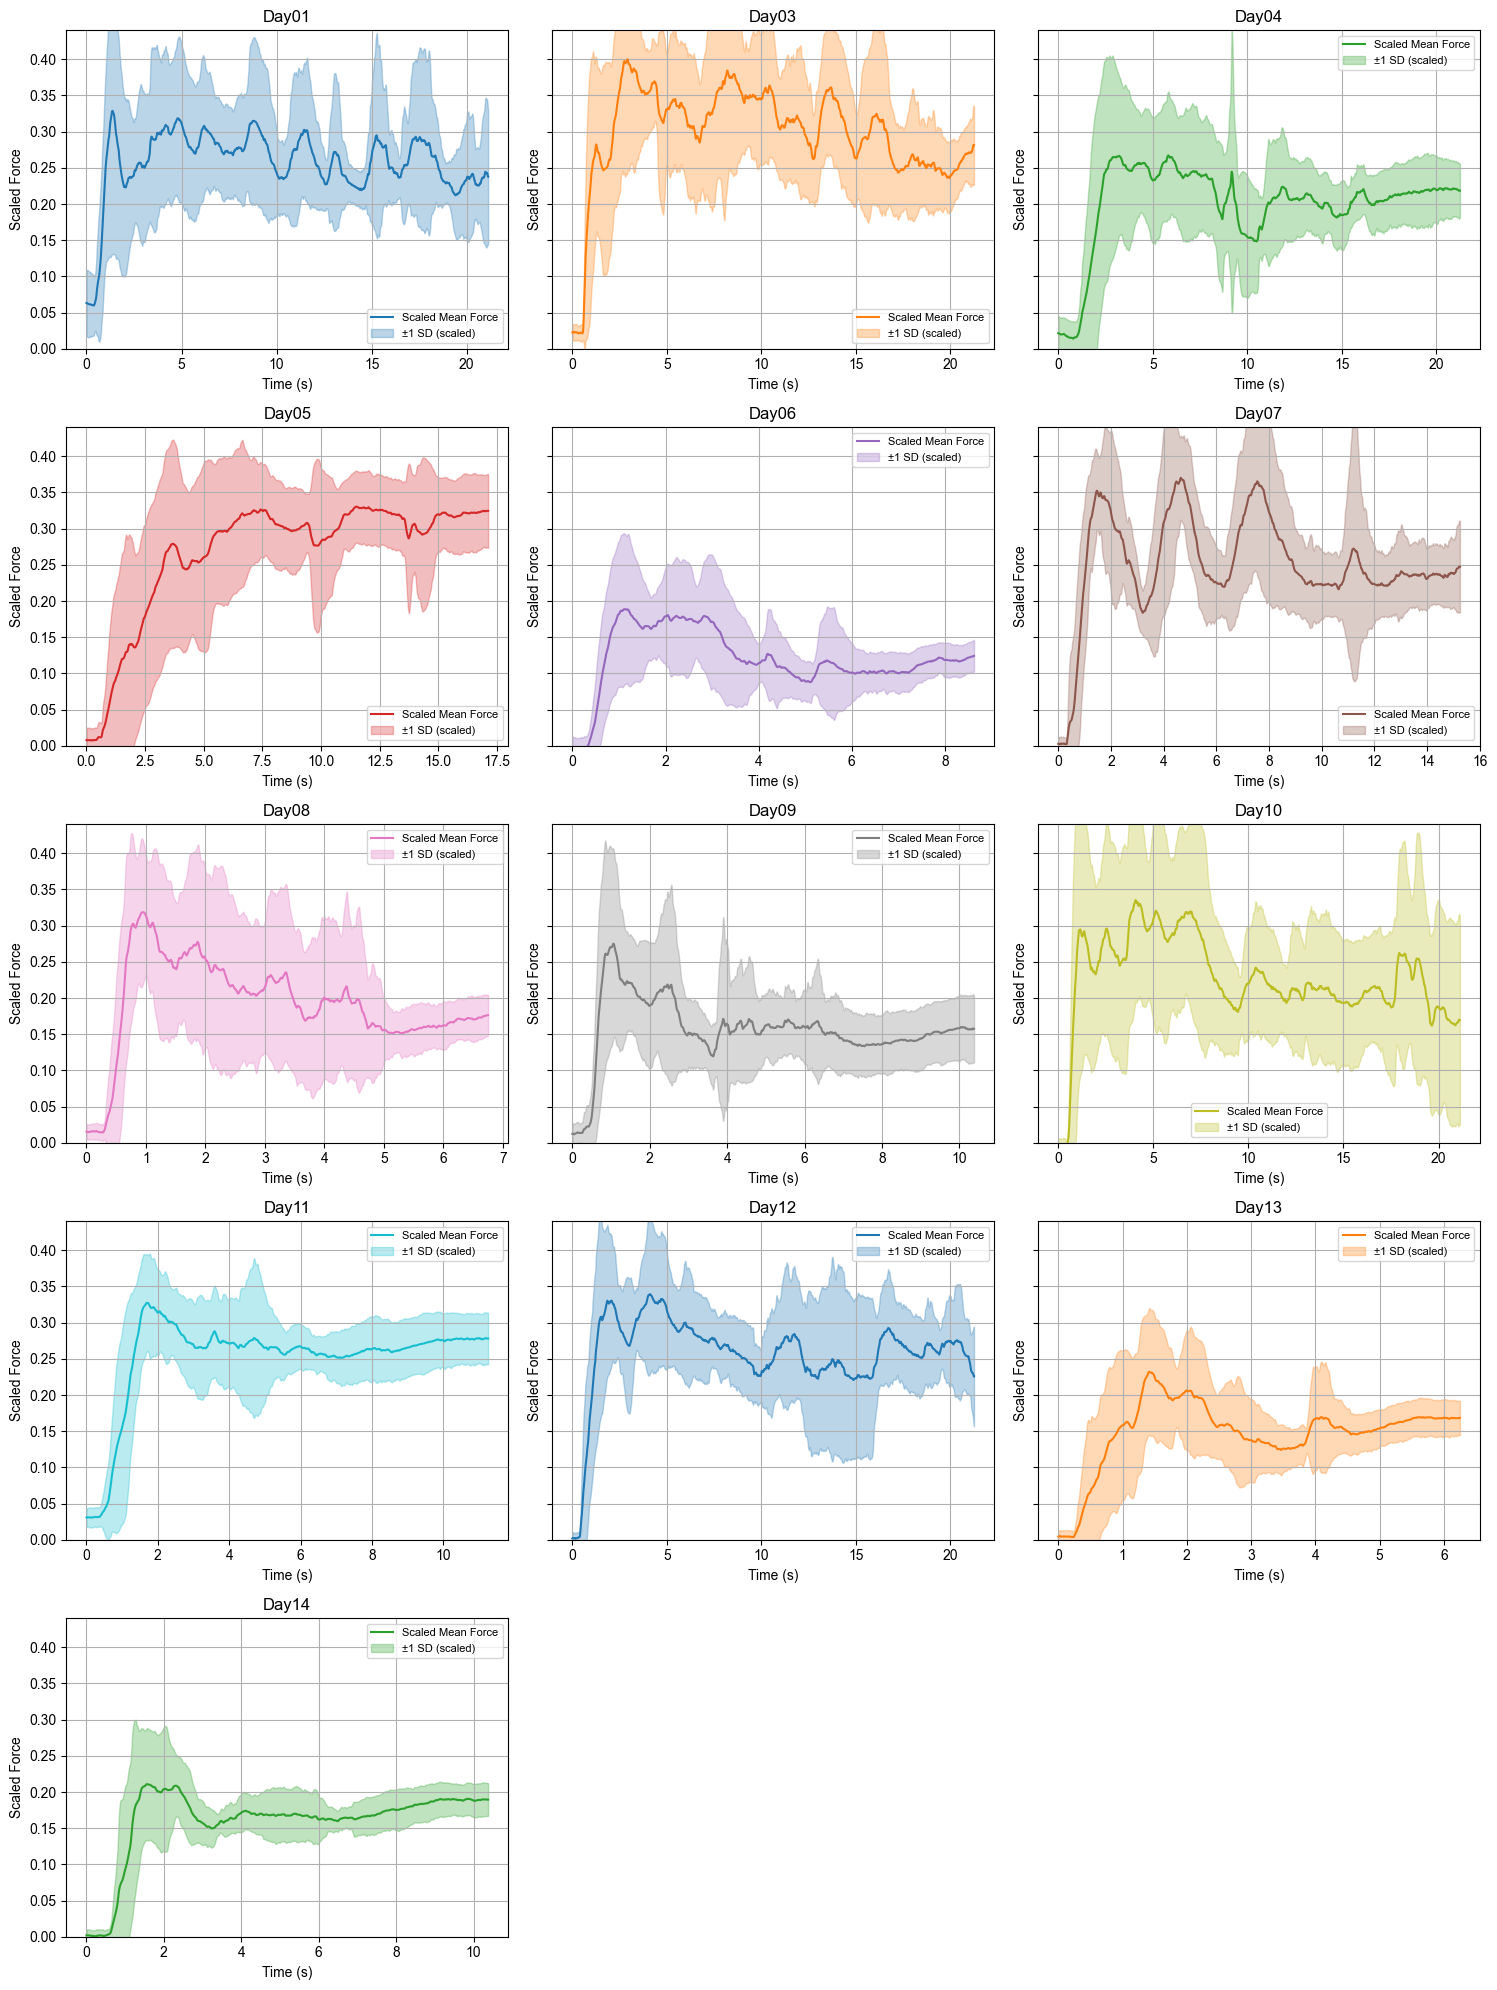

In [142]:
from functions_experimental_data_Bräckleinexp.scale_force_data import *
import os
import re
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.interpolate import interp1d

def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)
    return int(match.group(1)) if match else 0

def compute_and_save_avg_force(directory_path, save_dir, file_prefix="avg_force", target_max=0.5, fsamp=2048, plot=True):
    """
    Compute average force trajectories per day, scale to target_max, and save to .npy files.

    Parameters:
        directory_path (str): Path to the directory containing .pkl files.
        save_dir (str): Path where scaled .npy files will be saved.
        file_prefix (str): Prefix for saved filenames (default: "avg_force").
        target_max (float): Target maximum force value after scaling (default: 0.5).
        fsamp (int): Sampling rate in Hz (default: 2048).
        plot (bool): Whether to generate force plots (default: True).
    """
    
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]
    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day is not None:
            files_by_day.setdefault(day, []).append(file)

    session_days = sorted(files_by_day.keys())
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    average_force_by_day = {}
    time_by_day = {}

    for day in session_days:
        session_files = files_by_day[day]
        force_trials = []
        trial_lengths = []
        raw_forces = []

        for file_name in session_files:
            file_path = os.path.join(directory_path, file_name)
            with open(file_path, 'rb') as f:
                data = pickle.load(f)
            force = np.array(data['Force'].tolist())[0]
            raw_forces.append(force)
            trial_lengths.append(len(force))

        min_length = min(trial_lengths)
        new_time = np.linspace(0, 1, min_length)

        for force in raw_forces:
            old_time = np.linspace(0, 1, len(force))
            interp_func = interp1d(old_time, force, kind='linear')
            downsampled = interp_func(new_time)
            force_trials.append(downsampled)

        force_trials = np.array(force_trials)
        mean_force = np.mean(force_trials, axis=0)
        std_force = np.std(force_trials, axis=0)
        time_axis = np.linspace(0, len(raw_forces[0]) / fsamp, min_length)

        average_force_by_day[day] = {'mean': mean_force, 'std': std_force}
        time_by_day[day] = time_axis

    # Global max for scaling
    all_max = max(np.max(average_force_by_day[day]['mean']) for day in session_days)
    scaling_factor = target_max / all_max

    print(f"Global maximum force (before scaling): {all_max:.4f}")
    print(f"Scaling factor to apply: {scaling_factor:.4f}")

    os.makedirs(save_dir, exist_ok=True)

    for day in session_days:
        mean_force = average_force_by_day[day]['mean']
        scaled_force = mean_force * scaling_factor      
        filename = f"{file_prefix}_{day}_scaled{int(target_max * 10):02d}.npy"
        save_path = os.path.join(save_dir, filename)
        np.save(save_path, scaled_force)
        print(f"Saved scaled force for {day} to {save_path}")
    
    if plot:
        cols = 3
        rows = int(np.ceil(len(session_days) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows), sharex=False, sharey=True)
        axes = axes.flatten()
        cmap = cm.get_cmap("tab10")

        for i, day in enumerate(session_days):
            mean = average_force_by_day[day]['mean'] * scaling_factor
            std = average_force_by_day[day]['std'] * scaling_factor
            t = time_by_day[day]
            color = cmap(i % 10)

            ax = axes[i]
            ax.plot(t, mean, color=color, label='Scaled Mean Force')
            ax.fill_between(t, mean - std, mean + std, color=color, alpha=0.3, label='±1 SD (scaled)')
            ax.set_title(f"{day}", fontsize=12)
            ax.set_xlabel("Time (s)")
            ax.set_ylabel("Scaled Force")
            ax.set_ylim([0, target_max * 1.1])
            ax.grid(True)
            ax.legend(fontsize=8)

        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])

        plt.tight_layout()
        plt.show()

compute_and_save_avg_force( directory_path="/Users/nmt121/Desktop/DATA/S1",
    save_dir="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/TEST/",
    file_prefix="avg_force_Day",
    target_max=0.4)


Global maximum force (before scaling): 0.2469
Scaling factor to apply: 4.4559
Saved scaled force for Day01 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/Last_trial/last_trial_force_Day01_scaled11.npy
Saved scaled force for Day03 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/Last_trial/last_trial_force_Day03_scaled11.npy
Saved scaled force for Day04 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/Last_trial/last_trial_force_Day04_scaled11.npy
Saved scaled force for Day05 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/Last_trial/last_trial_force_Day05_scaled11.npy
Saved scaled force for Day06 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/Last_trial/last_trial_force_Day06_scaled11.npy
Saved scaled force for Day07 to /Users/nmt121/Desktop/Reposito

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_44301/2403099763.py:72: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab10")


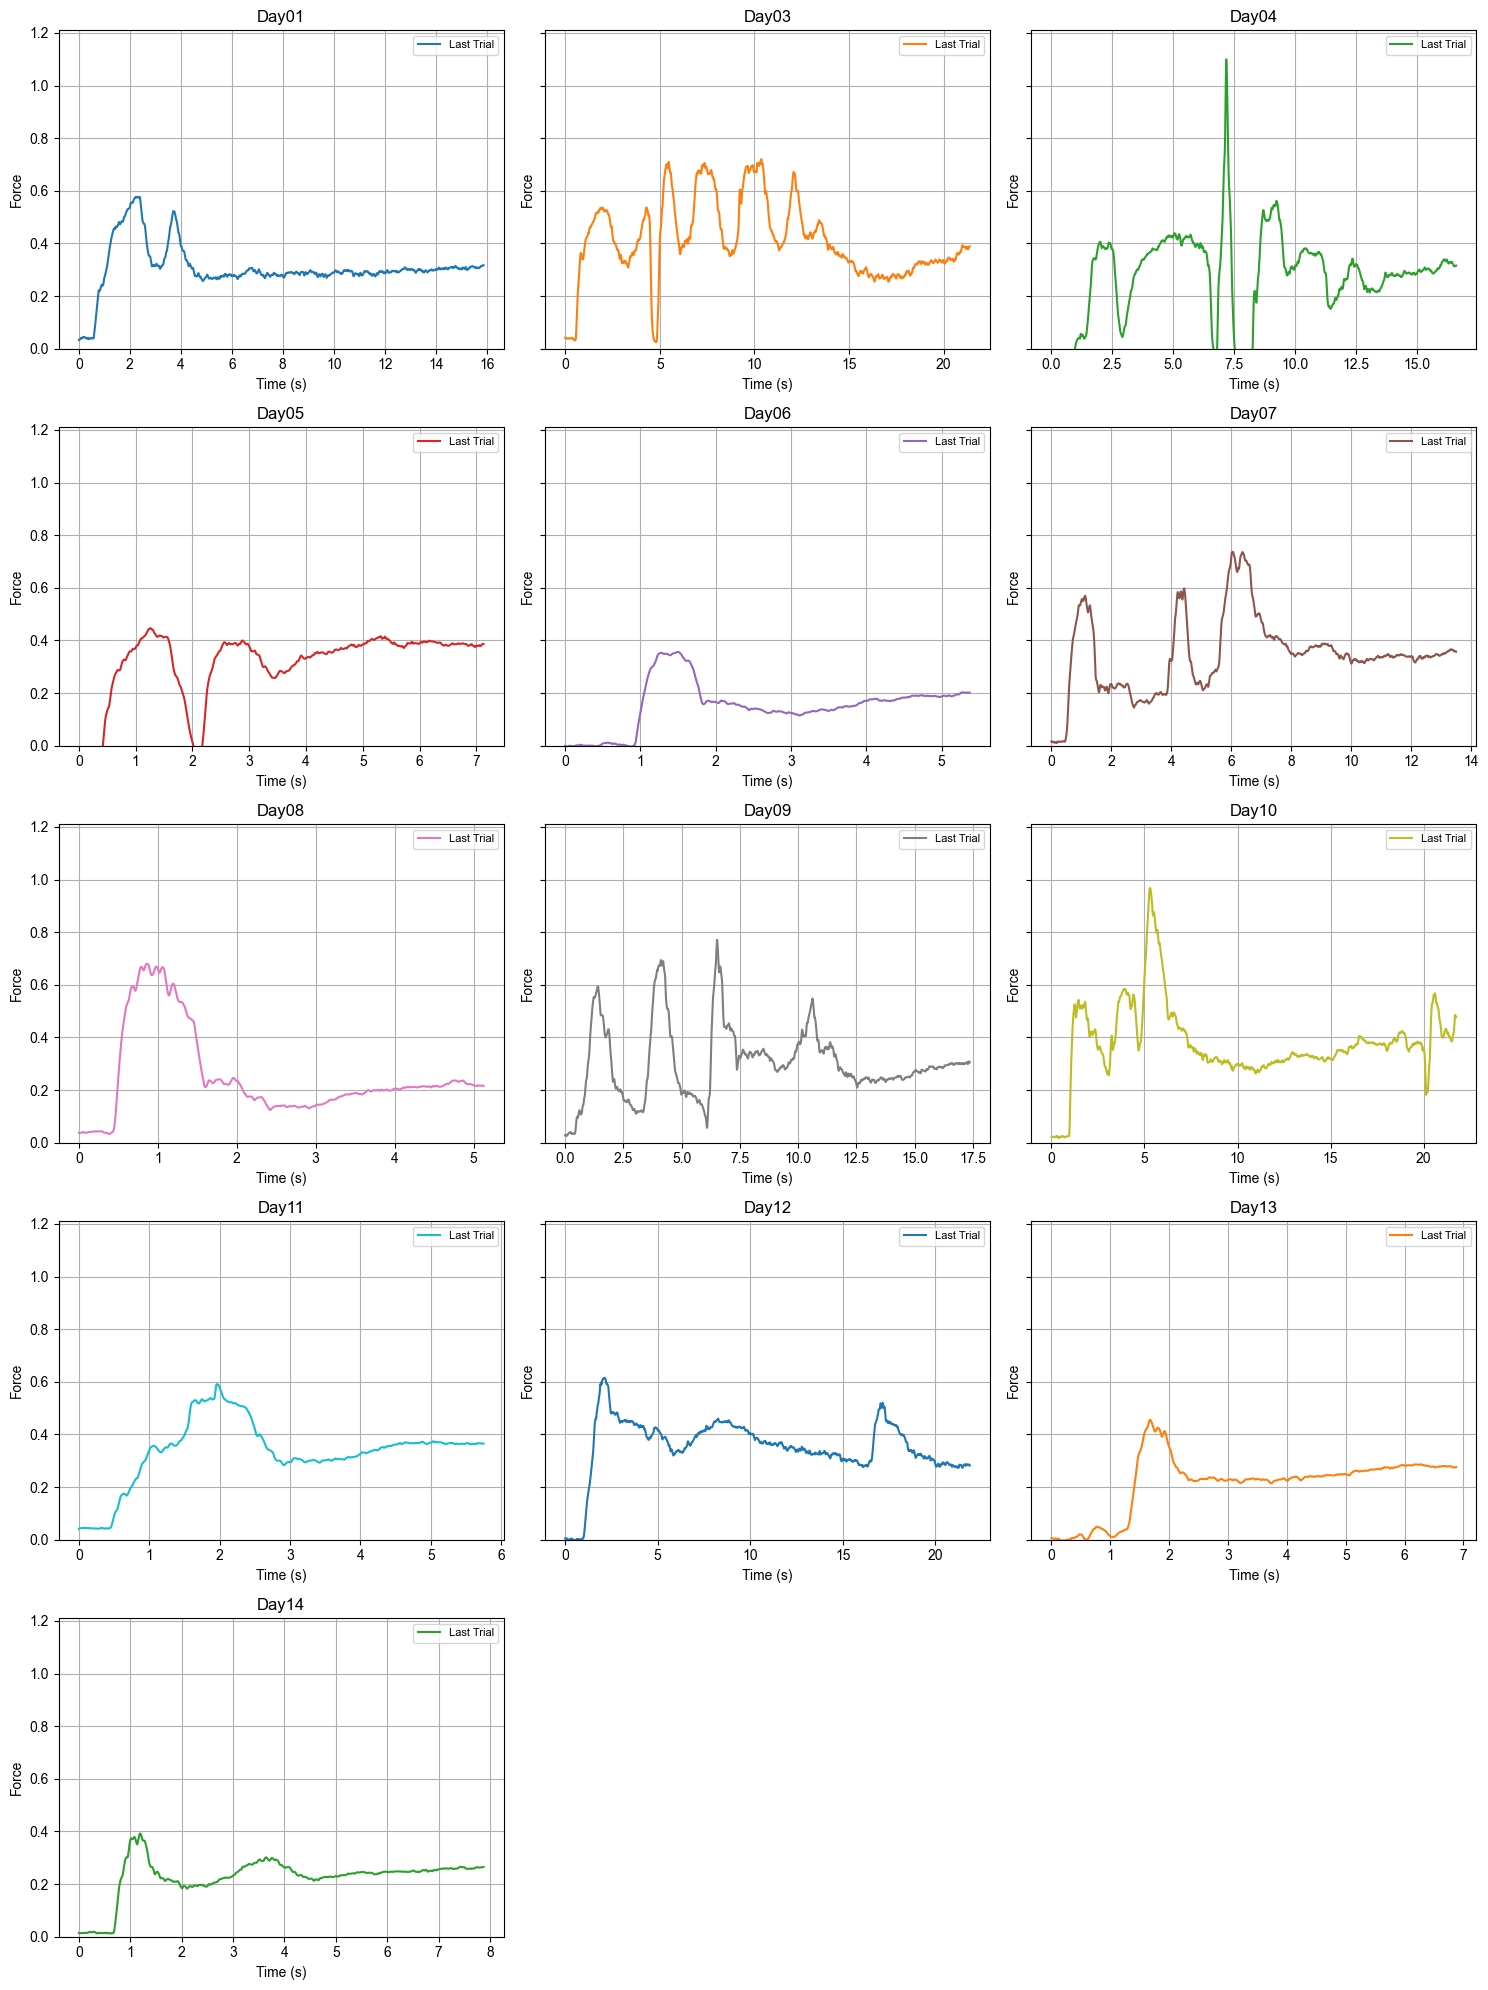

In [148]:
import os
import re
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.interpolate import interp1d

def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)
    return int(match.group(1)) if match else 0

def compute_and_save_last_trial_force(directory_path, save_dir, file_prefix="last_force", target_max=0.5, fsamp=2048, plot=True):
    """
    For each day, take only the last trial, scale it, and save it as .npy file. Optionally plot.
    """
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]
    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day is not None:
            files_by_day.setdefault(day, []).append(file)

    session_days = sorted(files_by_day.keys())
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    last_force_by_day = {}
    time_by_day = {}

    for day in session_days:
        last_file = files_by_day[day][-1]
        file_path = os.path.join(directory_path, last_file)
        with open(file_path, 'rb') as f:
            data = pickle.load(f)
        force = np.array(data['Force'].tolist())[0]
        time_axis = np.linspace(0, len(force) / fsamp, len(force))

        last_force_by_day[day] = force
        time_by_day[day] = time_axis

    if not last_force_by_day:
        print("No valid force data found. Exiting.")
        return

    # Global max for scaling
    all_max = max(np.max(force) for force in last_force_by_day.values())
    scaling_factor = target_max / all_max

    print(f"Global maximum force (before scaling): {all_max:.4f}")
    print(f"Scaling factor to apply: {scaling_factor:.4f}")

    os.makedirs(save_dir, exist_ok=True)

    for day in session_days:
        scaled_force = last_force_by_day[day] * scaling_factor
        filename = f"{file_prefix}_{day}_scaled{int(round(target_max * 10)):02d}.npy"
        save_path = os.path.join(save_dir, filename)
        np.save(save_path, scaled_force)
        print(f"Saved scaled force for {day} to {save_path}")

    # Plotting
    if plot:
        cols = 3
        rows = int(np.ceil(len(session_days) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows), sharex=False, sharey=True)
        axes = axes.flatten()
        cmap = cm.get_cmap("tab10")

        for i, day in enumerate(session_days):
            t = time_by_day[day]
            scaled = last_force_by_day[day] * scaling_factor
            color = cmap(i % 10)

            ax = axes[i]
            ax.plot(t, scaled, color=color, label='Last Trial')
            ax.set_title(f"{day}", fontsize=12)
            ax.set_xlabel("Time (s)")
            ax.set_ylabel("Force")
            ax.set_ylim([0, target_max * 1.1])
            ax.grid(True)
            ax.legend(fontsize=8)

        # Remove unused axes
        for j in range(len(session_days), len(axes)):
            fig.delaxes(axes[j])

        plt.tight_layout()
        plt.show(block=True)  # <-- Ensures the figure displays even in some IDEs


compute_and_save_last_trial_force(
    directory_path="/Users/nmt121/Desktop/DATA/S1",
    save_dir="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/Last_trial",
    file_prefix="last_trial_force",
    target_max=1.1,
    fsamp=2048,
    plot=True
)


In [105]:
# def plot_avg_force_for_day(directory_path, save_path, target_day="Day14", fsamp=2048, target_max=0.5, scale=True):
#     """
#     Compute and plot average force trajectory for a specific day with shading for ±1 SD.
#     Optionally scales the mean to a target max value.
#     """
#     import os
#     import re
#     import pickle
#     import numpy as np
#     import matplotlib.pyplot as plt
#     from scipy.interpolate import interp1d

#     def extract_day(filename):
#         match = re.search(r"(Day\d{2})", filename)
#         return match.group(1) if match else None

#     def extract_trial(filename):
#         match = re.search(r'_(\d+)[^0-9]', filename)
#         return int(match.group(1)) if match else 0

#     pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl") and extract_day(f) == target_day]
#     if not pkl_files:
#         print(f"No files found for {target_day} in {directory_path}")
#         return

#     pkl_files.sort(key=extract_trial)

#     raw_forces = []
#     trial_lengths = []

#     for file in pkl_files:
#         with open(os.path.join(directory_path, file), 'rb') as f:
#             data = pickle.load(f)
#         force = np.array(data['Force'].tolist())[0]
#         raw_forces.append(force)
#         trial_lengths.append(len(force))

#     min_length = min(trial_lengths)
#     new_time = np.linspace(0, 1, min_length)
#     force_trials = []

#     for force in raw_forces:
#         old_time = np.linspace(0, 1, len(force))
#         interp_func = interp1d(old_time, force, kind='linear')
#         downsampled = interp_func(new_time)
#         force_trials.append(downsampled)

#     force_trials = np.array(force_trials)
#     mean_force = np.mean(force_trials, axis=0)
#     std_force = np.std(force_trials, axis=0)
#     time_axis = np.linspace(0, min_length / fsamp, min_length)

#     if scale:
#         original_max = np.max(mean_force)
#         scaling_factor = target_max / original_max
#         mean_force *= scaling_factor
#         std_force *= scaling_factor

#     # Plot
#     plt.figure(figsize=(7, 4))  # less wide
#     plt.plot(time_axis, mean_force, color='blue', linewidth=3)
#     plt.fill_between(time_axis, mean_force - std_force, mean_force + std_force,
#                      color='blue', alpha=0.3)

#     plt.xlabel("Time (s)", fontsize=22)
#     plt.ylabel("Force (a.u.)", fontsize=22)
#     plt.xticks(fontsize=20)
#     plt.yticks(fontsize=20)
#     plt.ylim(-0.02, 0.2)

#     # Remove top and right spines
#     ax = plt.gca()
#     ax.spines['top'].set_visible(False)
#     ax.spines['right'].set_visible(False)

#     plt.tight_layout()
#     os.makedirs(os.path.dirname(save_path), exist_ok=True)
#     plt.savefig(save_path, dpi=300, bbox_inches='tight')
#     plt.show()
#     print(f"✅ Plot saved to: {save_path}")
    
# plot_avg_force_for_day(
#     directory_path="/Users/nmt121/Desktop/DATA/S1",
#     save_path="/Users/nmt121/Desktop/ForceTrajectory_Day14_S1_unscaled.pdf",
#     target_day="Day14",
#     fsamp=2048,
#     scale=False
# )



[16.67383291 16.94592411 16.85820739 16.64583196 16.6521317  16.74233546
 16.92136503 16.82527998 16.48983346 16.70162611 16.29178053 16.71283533
 16.50783629 16.55558439 16.13439623 16.27650286 16.22416941 16.2101254
 16.35930016 16.3613963  16.1077179  16.20019756 16.31214071 16.90772788
 16.57518524 16.33782404 16.2806333  17.00500923 16.55143308 16.5492505
 15.89735978 15.93137658 15.97186848 17.22868115 16.32588575 16.91186671
 16.12308826 15.51369216 15.99757732 15.62774189 16.10082814 16.70439518
 17.12351409 15.67833611 15.54510395 15.32221423 16.72577985 15.72093361
 16.60054118 15.37105868 16.56556152 17.03515406 15.98302218 16.52497661
 16.52289317 17.1905127  16.30964457 15.02323594 16.98294077 15.65784608
 14.7505423  15.24102353 15.32201096 14.54865792 17.17294559 14.66261001
 17.86684534 14.61710201 17.87620064 14.87896661 16.15309395 14.16638824
 14.59649684 15.04558813 15.8622781  14.45623475 13.96195534 14.05105216
 15.1307707  14.51636101 13.16532507 16.03147513 13.3

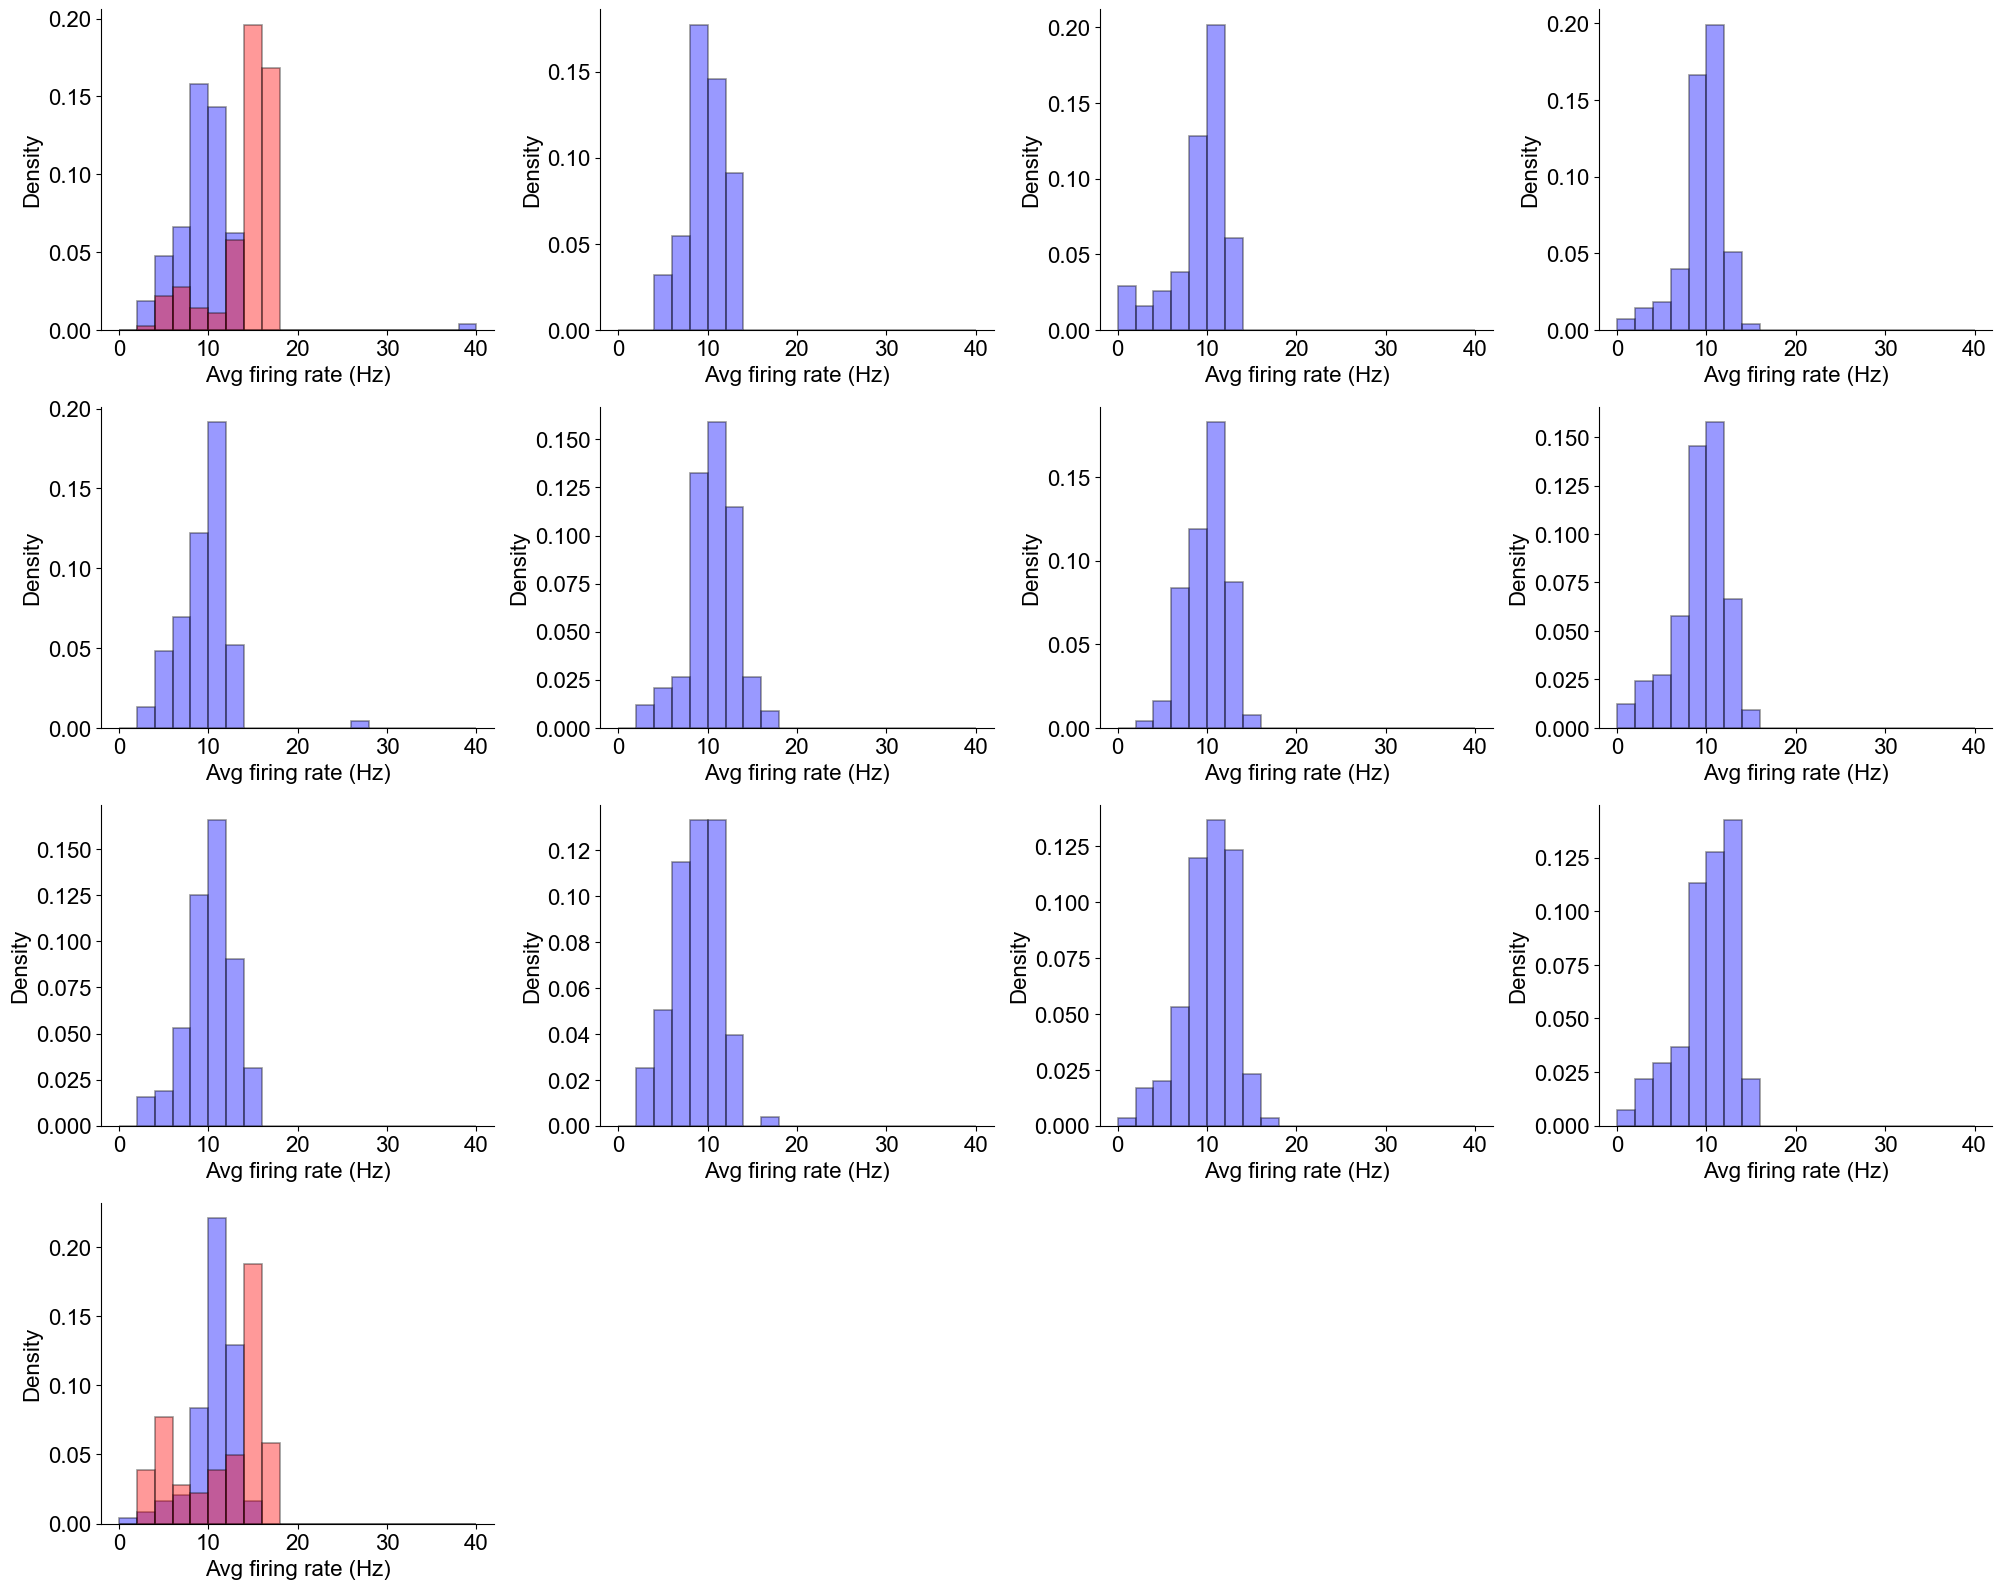

In [150]:
import os
import re
import pickle
import h5py
import numpy as np
import matplotlib.pyplot as plt



def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return int(match.group(1)[3:]) if match else None

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)
    return int(match.group(1)) if match else 0

def compute_avg_firing_rate(spike_times, sampling_rate):
    if len(spike_times) < 2:
        return None
    ISIs = np.diff(spike_times) / sampling_rate
    return 1 / np.mean(ISIs)

def load_simulated_rates(jld2_file_paths):
    sim_rates_by_day = {}
    for path in jld2_file_paths:
        day_match = re.search(r'force(\d+)_firing_rates_last_trial\.jld2', path)
        if not day_match:
            continue
        day = int(day_match.group(1))

        with h5py.File(path, 'r') as f:
            if 'avg_rates_per_neuron' in f:
                rates = f['avg_rates_per_neuron'][:]
                sim_rates_by_day[day] = rates
                print(sim_rates_by_day[day])
            else:
                print(f"'avg_rates_per_neuron' not found in {path}")
    return sim_rates_by_day

def compute_firing_rate_histograms_with_sim(folder_path, Fsamp, jld2_file_paths):
    sim_data = load_simulated_rates(jld2_file_paths)
    pkl_files = sorted(
        [f for f in os.listdir(folder_path) if f.endswith('.pkl')],
        key=lambda x: (extract_day(x), extract_trial(x))
    )
    day_files = {}
    for file in pkl_files:
        day = extract_day(file)
        if day is not None:
            day_files.setdefault(day, []).append(file)

    n_days = len(day_files)
    n_cols = 4
    n_rows = int(np.ceil(n_days / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
    axes = axes.flatten()

    for i, (day, files) in enumerate(sorted(day_files.items())):
        all_firing_rates = []
        for file in files:
            with open(os.path.join(folder_path, file), 'rb') as f:
                data = pickle.load(f)
            MU_array = np.array(data['MU'])

            for neuron_idx in range(MU_array.shape[0]):
                spike_times = np.where(MU_array[neuron_idx] == 1)[0]
                fr = compute_avg_firing_rate(spike_times, Fsamp)
                if fr is not None and fr <= 80:
                    all_firing_rates.append(fr)

        ax = axes[i]
        bin_edges = np.linspace(0, 40, 21)

        ax.hist(all_firing_rates, bins=bin_edges, color='blue', alpha=0.4,
                label='Experimental', density=True, edgecolor='black', linewidth=1.2)

        if day in sim_data:
            ax.hist(sim_data[day], bins=bin_edges, color='red', alpha=0.4,
                    label='Simulated', density=True, edgecolor='black', linewidth=1.2)

        # ax.set_title(f'Day {day}: {len(all_firing_rates)} neurons')  # Title removed
        ax.set_xlabel('Avg firing rate (Hz)', fontsize=16)
        ax.set_ylabel('Density', fontsize=16)

        # Remove legend
        # ax.legend()

        # Remove top and right spines
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)

        # Make ticks bigger
        ax.tick_params(axis='both', which='major', labelsize=16)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    return fig



folder_path = "/Users/nmt121/Desktop/DATA/S1"
Fsamp = 2048

jld2_file_paths = [
    
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force1_firing_rates_last_trial.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force5_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force6_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force8_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force9_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force10_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force11_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force12_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force13_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force14_firing_rates_last_trial.jld2',
    
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force2_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force13_firing_rates.jld2',
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force1_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force2_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force5_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force10_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force11_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force12_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force13_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force14_firing_rates.jld2',
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force1_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force8_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force9_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force10_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force11_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force12_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force13_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force14_firing_rates.jld2',
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force1_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force5_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force8_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force9_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force10_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force11_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force12_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force13_firing_rates.jld2', 
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force14_firing_rates.jld2',
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force1_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force2_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force3_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force4_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force5_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force6_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force7_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force8_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force9_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force10_firing_rates7.jld2',




]

fig = compute_firing_rate_histograms_with_sim(folder_path, Fsamp, jld2_file_paths)
# plt.savefig('/Users/nmt121/Desktop/Figures/FRdistributions_S2.pdf', dpi=300, bbox_inches='tight')
plt.show()



## Get rasters for each of the trials

In [340]:
# fig = create_raster('/Users/nmt121/Desktop/DATA/S1/', Fsamp=1000, extract_day=extract_day, extract_trial=extract_trial)
# plt.show(fig)
# fig.savefig('/Users/nmt121/Desktop/trial_plot.pdf', dpi=300, bbox_inches='tight')

# Behavioral analysis

## Plot force trajectories for every day and every trial

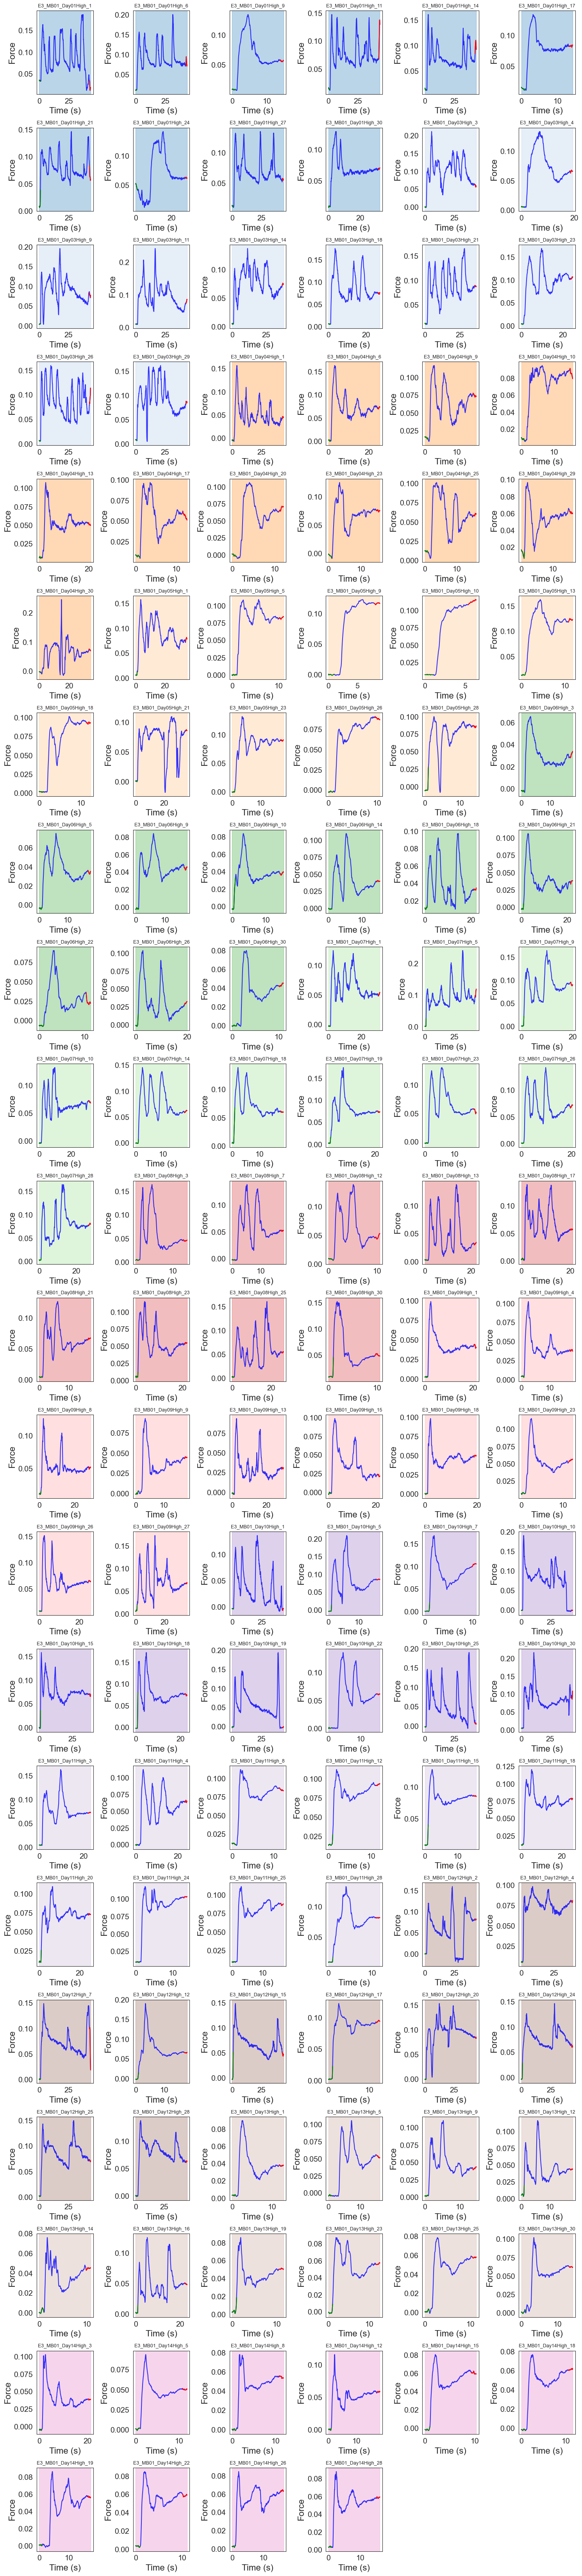

In [115]:
from functions_experimental_data_Bräckleinexp.force_trajectories import *
fsamp = 2048  
highlight_samples = int(3 * fsamp)  #in case one wants to highlight part of the trajectory
fig = create_force_plots_by_day(directory_path='/Users/nmt121/Desktop/DATA/S1/',fsamp=1000,highlight_samples=1000,extract_day=extract_day,extract_trial=extract_trial)
# plt.show(fig)
# # plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7force.pdf', dpi=300, bbox_inches='tight')

### Plot force trajectories from 2 first and 2 last days 

In [505]:
# from functions_experimental_data_Bräckleinexp.force_trajectories import *
# plot_force_trials(directory_path="/Users/nmt121/Desktop/DATA/S7",output_path="/Users/nmt121/Desktop/Figures/S7force.pdf")

## Measure smoothness of the force signal 

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_6352/2226262292.py:137: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=df, x="Group", y="Smoothness", hue="Day",dodge=True, jitter=0.25, alpha=0.5, size=8,ax=ax, palette="tab10", edgecolor='gray', linewidth=0.2)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_6352/2226262292.py:152: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["First sessions", "Last sessions"], fontsize=16)


(83.0, 5.999230448970428e-05)

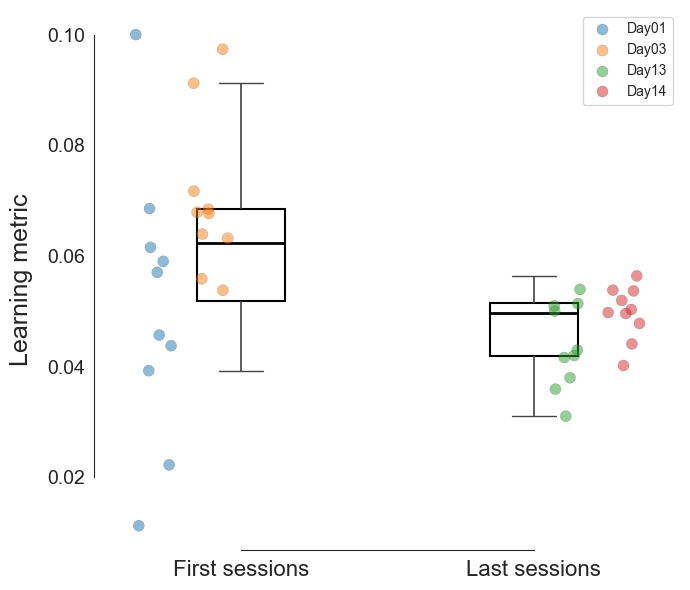

In [110]:
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  


# def compute_smoothness(force_signal, fsamp, high_freq_threshold=5.0):
#     # Remove DC offset
#     # force_signal = force_signal - np.mean(force_signal)

#     # FFT
#     freqs = np.fft.rfftfreq(len(force_signal), d=1/fsamp)
#     fft_vals = np.fft.rfft(force_signal)

#     # Power spectrum (normalized)
#     power_spectrum = (np.abs(fft_vals) ** 2) / len(force_signal)

#     # Total power in fast oscillations
#     smoothness = np.sum(power_spectrum[freqs > high_freq_threshold])

#     return smoothness


def compute_smoothness(force_signal, fsamp, high_freq_threshold=5.0):
    
    freqs = np.fft.rfftfreq(len(force_signal), d=1/fsamp)
    amp_spectrum = np.abs(np.fft.rfft(force_signal)) / len(force_signal)
    smoothness= np.sum(amp_spectrum[freqs > high_freq_threshold])
    
    return smoothness

# def compute_smoothness(force_signal, fsamp, high_freq_threshold=5.0):
#     freqs = np.fft.rfftfreq(len(force_signal), d=1/fsamp)
#     amp_spectrum = np.abs(np.fft.rfft(force_signal)) / len(force_signal)
    
#     high_freq_amp = np.sum(amp_spectrum[freqs > high_freq_threshold])
#     total_amp = np.sum(amp_spectrum)
    
#     smoothness = high_freq_amp / total_amp  # ratio of high-frequency content
#     return smoothness





# def compute_smoothness(force_signal, fsamp):
#     # Time step
#     dt = 1 / fsamp
    
#     # First derivative (velocity of force change)
#     first_derivative = np.gradient(force_signal, dt)
    
#     # Second derivative (acceleration of force change)
#     second_derivative = np.gradient(first_derivative, dt)
    
#     smoothness= np.var(second_derivative)
#     # Variance as smoothness metric
#     return smoothness



# def compute_smoothness(force_signal, fsamp,
#                        high_freq_threshold=3.0,  # catch 6–9 Hz content
#                        fmin=1.0, fmax=10.0):
#     # 1) remove DC so 0 Hz doesn't dominate
#     x = np.asarray(force_signal, float) - np.mean(force_signal)

#     # 2) FFT → power spectrum normalized by length
#     freqs = np.fft.rfftfreq(len(x), d=1/fsamp)
#     X = np.fft.rfft(x)
#     power = (np.abs(X) ** 2) / len(x)

#     # 3) integrate power: fast / total in a focused band
#     band = (freqs >= fmin) & (freqs <= fmax)
#     fast = (freqs >= high_freq_threshold) & (freqs <= fmax)

#     hf_power   = np.trapz(power[fast],  freqs[fast])
#     total_band = np.trapz(power[band],  freqs[band]) + 1e-20

#     smoothness = hf_power / total_band   # higher = more HF = less smooth
#     return float(smoothness)




def compute_signal_smoothness(directory_path, fsamp):
    import matplotlib.patches as patches
    from matplotlib import rcParams

    # Set font globally
    rcParams['font.family'] = 'Arial'
    rcParams['axes.labelsize'] = 16
    rcParams['xtick.labelsize'] = 14
    rcParams['ytick.labelsize'] = 14

    # 1. Load and group files
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]
    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day is not None:
            files_by_day.setdefault(day, []).append(file)

    session_days = sorted(files_by_day.keys())
    if len(session_days) < 4:
        raise ValueError("Need at least 4 days to compute first vs last two.")

    first_days = session_days[:2]
    last_days = session_days[-2:]

    records = []
    for group_label, group_days in zip(["First sessions", "Last sessions"], [first_days, last_days]):
        for day in group_days:
            files_by_day[day].sort(key=extract_trial)
            for file_name in files_by_day[day]:
                file_path = os.path.join(directory_path, file_name)
                with open(file_path, 'rb') as f:
                    data = pickle.load(f)
                force_signal = np.array(data['Force'].tolist())[0]
                smoothness = compute_smoothness(force_signal, fsamp)
                records.append({
                    "Group": group_label,
                    "Day": day,
                    "Smoothness": smoothness
                })

    df = pd.DataFrame(records)
    

    plt.figure(figsize=(7, 6))
    ax = plt.gca()

    # Transparent colored dots by session
    sns.stripplot(data=df, x="Group", y="Smoothness", hue="Day",dodge=True, jitter=0.25, alpha=0.5, size=8,ax=ax, palette="tab10", edgecolor='gray', linewidth=0.2)

    # Standard boxplot (Q1–Q3 + median)
    sns.boxplot(data=df, x="Group", y="Smoothness",showcaps=True, showfliers=False,whiskerprops={'linewidth': 1.2},boxprops={'facecolor': 'none', 'edgecolor': 'black', 'linewidth': 1.5},medianprops={'color': 'black', 'linewidth': 2}, width=0.3,ax=ax)

    group_stats = df.groupby("Group")["Smoothness"].agg(["mean", "std", "count"])
    for i, group in enumerate(["First sessions", "Last sessions"]):
        mean_val = group_stats.loc[group, "mean"]
        std_val = group_stats.loc[group, "std"]
        n = group_stats.loc[group, "count"]
        sem = std_val / np.sqrt(n)


    ax.set_ylabel("Learning metric", fontsize=18, labelpad=10)
    ax.set_xlabel("")
    ax.set_xticklabels(["First sessions", "Last sessions"], fontsize=16)
    sns.despine(trim=True)


    plt.tight_layout()
    return plt.gcf()


def compute_statistical_difference(directory_path, fsamp, extract_day, extract_trial):
    
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]
    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day is not None:
            files_by_day.setdefault(day, []).append(file)

    session_days = sorted(files_by_day.keys())
    if len(session_days) < 4:
        raise ValueError("Need at least 4 days to compare first vs last two.")

    first_days = session_days[:2]
    last_days = session_days[-2:]

    records = []
    for group_label, group_days in zip(["First", "Last"], [first_days, last_days]):
        for day in group_days:
            files_by_day[day].sort(key=extract_trial)
            for file_name in files_by_day[day]:
                file_path = os.path.join(directory_path, file_name)
                with open(file_path, 'rb') as f:
                    data = pickle.load(f)
                force_signal = np.array(data['Force'].tolist())[0]
                smoothness = compute_smoothness(force_signal, fsamp)
                records.append({"Group": group_label, "Smoothness": smoothness})

    df = pd.DataFrame(records)

    # Run Mann–Whitney U test
    first_vals = df[df["Group"] == "First"]["Smoothness"].values
    last_vals = df[df["Group"] == "Last"]["Smoothness"].values
    stat, pval = mannwhitneyu(first_vals, last_vals, alternative='two-sided')
    return stat, pval

fig = compute_signal_smoothness('/Users/nmt121/Desktop/DATA/S1/', fsamp=2048)
# fig.savefig("/Users/nmt121/Desktop/Figures/learningmetric7_amplitudefft.pdf", dpi=300, bbox_inches='tight')


compute_statistical_difference('/Users/nmt121/Desktop/DATA/S7/', 2048, extract_day, extract_trial)



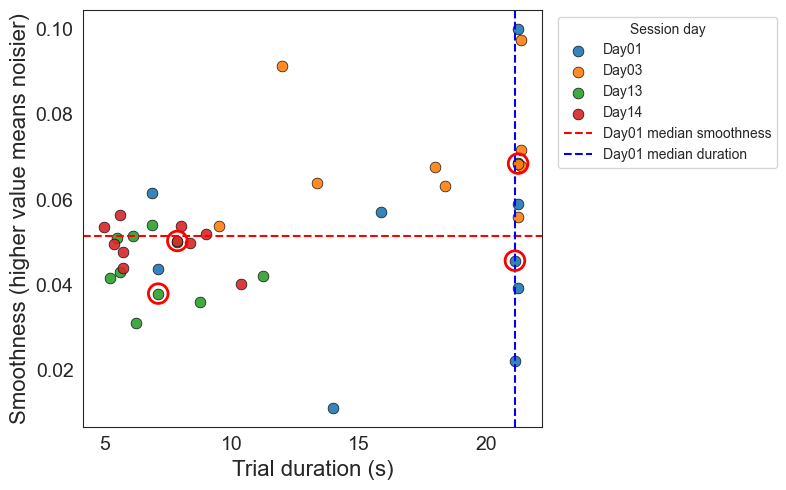

       Day  Trial                      File  TrialDur_s  Smoothness
6    Day01     21  E3_MB01_Day01High_21.pkl      21.125    0.045720
13   Day03     11  E3_MB01_Day03High_11.pkl      21.250    0.068481
22   Day04      9   E3_MB01_Day04High_9.pkl       7.875    0.051828
36   Day05     18  E3_MB01_Day05High_18.pkl       6.000    0.080721
42   Day06      5   E3_MB01_Day06High_5.pkl       8.750    0.034478
57   Day07     19  E3_MB01_Day07High_19.pkl      10.750    0.063988
67   Day08     23  E3_MB01_Day08High_23.pkl      10.750    0.044008
73   Day09      9   E3_MB01_Day09High_9.pkl       8.875    0.040275
84   Day10     15  E3_MB01_Day10High_15.pkl      18.875    0.059173
92   Day11      8   E3_MB01_Day11High_8.pkl       6.000    0.062577
108  Day12     25  E3_MB01_Day12High_25.pkl      21.375    0.062187
112  Day13      9   E3_MB01_Day13High_9.pkl       7.125    0.037995
129  Day14     28  E3_MB01_Day14High_28.pkl       7.875    0.050339


In [114]:
def extract_day(filename):
    m = re.search(r"(Day\d{2})", filename)
    return m.group(1) if m else None

def extract_trial(filename):
    m = re.search(r'_(\d+)[^0-9]', filename)
    return int(m.group(1)) if m else 0

def load_force(file_path):
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    try:
        x = np.array(data['Force']).squeeze()
        if x.ndim > 1:
            x = np.array(data['Force'].tolist())[0].squeeze()
    except Exception:
        x = np.array(data['Force'].tolist())[0].squeeze()
    return np.asarray(x, float)


def duration_vs_smoothness_scatter_with_median(
    directory_path, fsamp=2048, high_freq_threshold=5.0,
    keep_first_last=True, annotate=True, save_path=None
):
    # Collect files by day (ALL days)
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]
    files_by_day = {}
    for f in pkl_files:
        day = extract_day(f)
        if day is not None:
            files_by_day.setdefault(day, []).append(f)
    for day in files_by_day:
        files_by_day[day].sort(key=extract_trial)

    days_all = sorted(files_by_day.keys())
    # Days to plot (first 2 + last 2), but compute for all
    if keep_first_last and len(days_all) >= 4:
        days_to_plot = days_all[:2] + days_all[-2:]
    else:
        days_to_plot = days_all

    # Build records for ALL days
    records = []
    for day in days_all:
        for fname in files_by_day[day]:
            fpath = os.path.join(directory_path, fname)
            try:
                x = load_force(fpath)
            except Exception:
                continue
            trial_dur = len(x) / fsamp
            smoothness = compute_smoothness(x, fsamp, high_freq_threshold)
            records.append({
                "Day": day,
                "Trial": extract_trial(fname),
                "TrialDur_s": trial_dur,
                "Smoothness": smoothness,
                "File": fname
            })
    if not records:
        print("No valid trials found.")
        return None, None

    df_all = pd.DataFrame(records)

    # Picks (per-day median) for ALL days
    picks = []
    for day, g in df_all.groupby("Day", sort=True):
        mx = g["TrialDur_s"].median()
        my = g["Smoothness"].median()
        iqr_x = np.percentile(g["TrialDur_s"], 75) - np.percentile(g["TrialDur_s"], 25)
        iqr_y = np.percentile(g["Smoothness"], 75) - np.percentile(g["Smoothness"], 25)
        sx = iqr_x if iqr_x > 0 else (g["TrialDur_s"].std() or 1.0)
        sy = iqr_y if iqr_y > 0 else (g["Smoothness"].std() or 1.0)
        dist = np.sqrt(((g["TrialDur_s"]-mx)/sx)**2 + ((g["Smoothness"]-my)/sy)**2)
        pick = g.loc[dist.idxmin(), ["Day","Trial","File","TrialDur_s","Smoothness"]]
        picks.append(pick)
    selected_all = pd.DataFrame(picks)

    # === Plot ONLY the 4 days (or all, if <4) ===
    df_plot = df_all[df_all["Day"].isin(days_to_plot)].copy()
    selected_plot = selected_all[selected_all["Day"].isin(days_to_plot)].copy()

    fig, ax = plt.subplots(figsize=(8,5))
    for day, g in df_plot.groupby("Day"):
        ax.scatter(g["TrialDur_s"], g["Smoothness"], s=60,
                   edgecolor="black", linewidth=0.5, alpha=0.9, label=day)

    # highlight chosen trials (red ring) for plotted days
    for _, r in selected_plot.iterrows():
        ax.scatter(r["TrialDur_s"], r["Smoothness"], s=200, facecolors="none",
                   edgecolors="red", linewidths=2.0, zorder=6)

    # Median lines for the FIRST plotted day
    first_day = sorted(days_to_plot)[0]
    median_smoothness_first = df_plot[df_plot["Day"] == first_day]["Smoothness"].median()
    median_dur_first = df_plot[df_plot["Day"] == first_day]["TrialDur_s"].median()
    ax.axhline(median_smoothness_first, ls="--", color="red", lw=1.5, label=f"{first_day} median smoothness")
    ax.axvline(median_dur_first, ls="--", color="blue", lw=1.5, label=f"{first_day} median duration")

    ax.set_xlabel("Trial duration (s)")
    ax.set_ylabel("Smoothness (higher value means noisier)")
    ax.legend(title="Session day", bbox_to_anchor=(1.02,1), loc="upper left")
    ax.tick_params(axis='both', which='minor', length=4, width=1, color='black')

    plt.tight_layout()
    # if save_path:
        # plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    # Print ALL selected (not just the 4)
    print(selected_all)
    return df_all, selected_all



# Example:
df, selected = duration_vs_smoothness_scatter_with_median(
    '/Users/nmt121/Desktop/DATA/S1/', fsamp=2048, high_freq_threshold=5.0,
    keep_first_last=True, annotate=True,
    save_path="/Users/nmt121/Desktop/Figures/dur_vs_smoothness_S1.pdf"
)


## Compute FFT to see frequency content 

In [ ]:
# from functions_experimental_data_Bräckleinexp.FFT_function import *
# results = plot_fft_and_compute_metric_per_trial('/Users/nmt121/Desktop/DATA/S1/', fsamp=2048, fmin=10.0, max_freq=30)


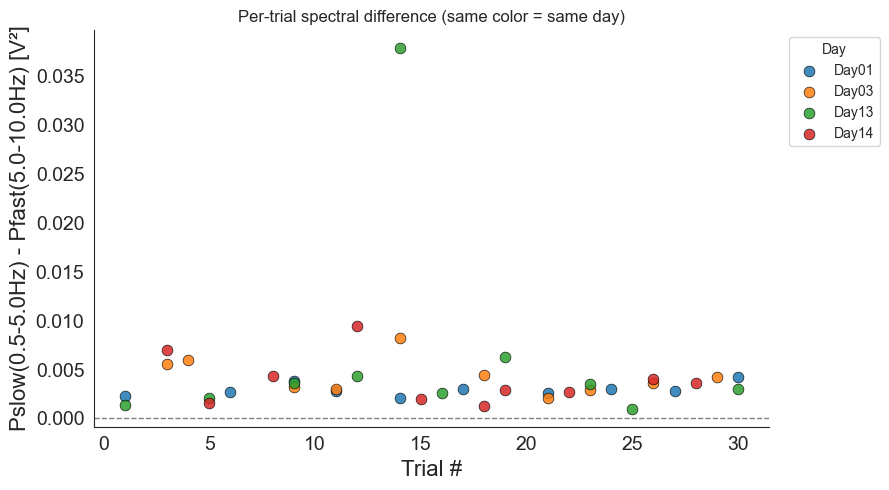

In [476]:
import os, re, pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import welch

# --- helpers ---
def extract_day(filename):
    m = re.search(r"(Day\d{2})", filename)
    return m.group(1) if m else None

def extract_trial(filename):
    m = re.search(r'_(\d+)[^0-9]', filename)
    return int(m.group(1)) if m else 0

def load_force(path):
    with open(path, 'rb') as f:
        d = pickle.load(f)
    try:
        x = np.array(d['Force']).squeeze()
        if x.ndim > 1:
            x = np.array(d['Force'].tolist())[0].squeeze()
    except Exception:
        x = np.array(d['Force'].tolist())[0].squeeze()
    x = np.asarray(x, float)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
    return x

def welch_psd(x, fs, nperseg_secs=2.0, detrend=True):
    nperseg = max(8, min(len(x), int(round(nperseg_secs*fs))))
    freqs, psd = welch(x, fs=fs, window='hann', nperseg=nperseg,
                       noverlap=nperseg//2,
                       detrend='constant' if detrend else False,
                       return_onesided=True, scaling='density')  # V^2/Hz
    return freqs, psd

def band_power(freqs, psd, f_lo, f_hi):
    m = (freqs >= f_lo) & (freqs < f_hi)
    if not np.any(m):
        return 0.0
    return np.trapz(psd[m], freqs[m])  # V^2

def spectral_diff_scatter(directory, fsamp=2048,low_floor_hz=0.5, split_hz=5.0, high_hz=10.0,nperseg_secs=2.0):
    # collect files by day
    pkl_files = [f for f in os.listdir(directory) if f.endswith('.pkl')]
    by_day = {}
    for f in pkl_files:
        d = extract_day(f)
        if d:
            by_day.setdefault(d, []).append(f)
    for d in by_day:
        by_day[d].sort(key=extract_trial)
    days_sorted = sorted(by_day)

    # keep first 2 and last 2 days only
    if len(days_sorted) > 4:
        days_sorted = days_sorted[:2] + days_sorted[-2:]

    palette = sns.color_palette("tab10", n_colors=len(days_sorted))
    day_color = {d: palette[i] for i, d in enumerate(days_sorted)}

    rows = []
    for d in days_sorted:
        for fname in by_day[d]:
            x = load_force(os.path.join(directory, fname))
            freqs, psd = welch_psd(x, fsamp, nperseg_secs=nperseg_secs, detrend=True)

            Pslow = band_power(freqs, psd, low_floor_hz, split_hz)
            Pfast = band_power(freqs, psd, split_hz, high_hz)
            
            total= Pslow +Pfast
            diff = Pfast/Pslow
        
            rows.append({
                "day": d,
                "trial": extract_trial(fname),
                "diff": diff,
                "Pslow": Pslow,
                "Pfast": Pfast
            })

    # plot
    sns.set_style("white")
    plt.figure(figsize=(9, 5))
    for d in days_sorted:
        trials = [r["trial"] for r in rows if r["day"] == d]
        vals   = [r["diff"] for r in rows if r["day"] == d]
        plt.scatter(trials, vals, s=60, alpha=0.85,
                    color=day_color[d], edgecolor="black", linewidth=0.5, label=d)
    plt.axhline(0, color="gray", linestyle="--", linewidth=1)
    plt.xlabel("Trial #")
    plt.ylabel(f"Pslow({low_floor_hz}-{split_hz}Hz) - Pfast({split_hz}-{high_hz}Hz) [V²]")
    plt.title("Per-trial spectral difference (same color = same day)")
    plt.legend(title="Day", bbox_to_anchor=(1.02,1), loc="upper left")
    sns.despine()
    plt.tight_layout()
    plt.show()

    return rows


rows = spectral_diff_scatter('/Users/nmt121/Desktop/DATA/S1/', fsamp=2048)


## Plot firing rate state space (in this case for two first and last 2 sessions)

In [554]:
# from functions_experimental_data_Bräckleinexp.plot_fr_trajectories import *
# plot_fr_trajectories(directory_path="/Users/nmt121/Desktop/DATA/S7",output_path="/Users/nmt121/Desktop/Figures/S7_FR_trajectory.pdf",clip_thresh=35)

## Plot peak count for each day

In [11]:
# from functions_experimental_data_Bräckleinexp.count_peaks_smoothnes import *

# directory_paths = {"S1": "/Users/nmt121/Desktop/DATA/S1", "S2": "/Users/nmt121/Desktop/DATA/S2","S3": "/Users/nmt121/Desktop/DATA/S3", "S4": "/Users/nmt121/Desktop/DATA/S4", "S6": "/Users/nmt121/Desktop/DATA/S6", "S7": "/Users/nmt121/Desktop/DATA/S7"}

# fig = create_peak_count_summary(directory_paths=directory_paths,fsamp=2048,extract_day=extract_day,extract_trial=extract_trial,lowpass_filter=lowpass_filter)

# # Save when ready
# # fig.savefig("/Users/nmt121/Desktop/Figures/peaks_summary.pdf", dpi=300, bbox_inches='tight')

# # Or display when ready
# plt.show(fig)


## Plot trial duration for all trials

In [14]:
# from functions_experimental_data_Bräckleinexp.trial_duration import *

# directory_paths = {"S1": "/Users/nmt121/Desktop/DATA/S1", "S2": "/Users/nmt121/Desktop/DATA/S2","S3": "/Users/nmt121/Desktop/DATA/S3", "S4": "/Users/nmt121/Desktop/DATA/S4", "S6": "/Users/nmt121/Desktop/DATA/S6", "S7": "/Users/nmt121/Desktop/DATA/S7"}

# plot_avg_trial_durations(directory_paths, fsamp=2048,save_path="/Users/nmt121/Desktop/Figures/avg_trial_durations.pdf")


### Plot trial durations from 2 first and 2 last days 

In [582]:
# from functions_experimental_data_Bräckleinexp.trial_duration import *
# fig = plot_first_last_two_days_duration_box('/Users/nmt121/Desktop/DATA/S1/', 2048)
# fig.savefig("/Users/nmt121/Desktop/Figures/trial_duration_session1.pdf", dpi=300, bbox_inches='tight')


In [583]:
# from functions_experimental_data_Bräckleinexp.trial_duration import *
# run_duration_stats('/Users/nmt121/Desktop/DATA/S7/', 2048)


## Plot decorrelation time (for how long the higher threshold motoneuron fires alone)

In [75]:
# from functions_experimental_data_Bräckleinexp.decorrelation_time import *
# plot_prolonged_firing_duration(directory_path="/Users/nmt121/Desktop/DATA/S1",fsamp=2048
#     # scatter_save_path="/Users/nmt121/Desktop/RESULTS_ DATA EXP/s1_scatter.pdf",
#     # trend_save_path="/Users/nmt121/Desktop/RESULTS_ DATA EXP/s1_trend.pdf"
# )


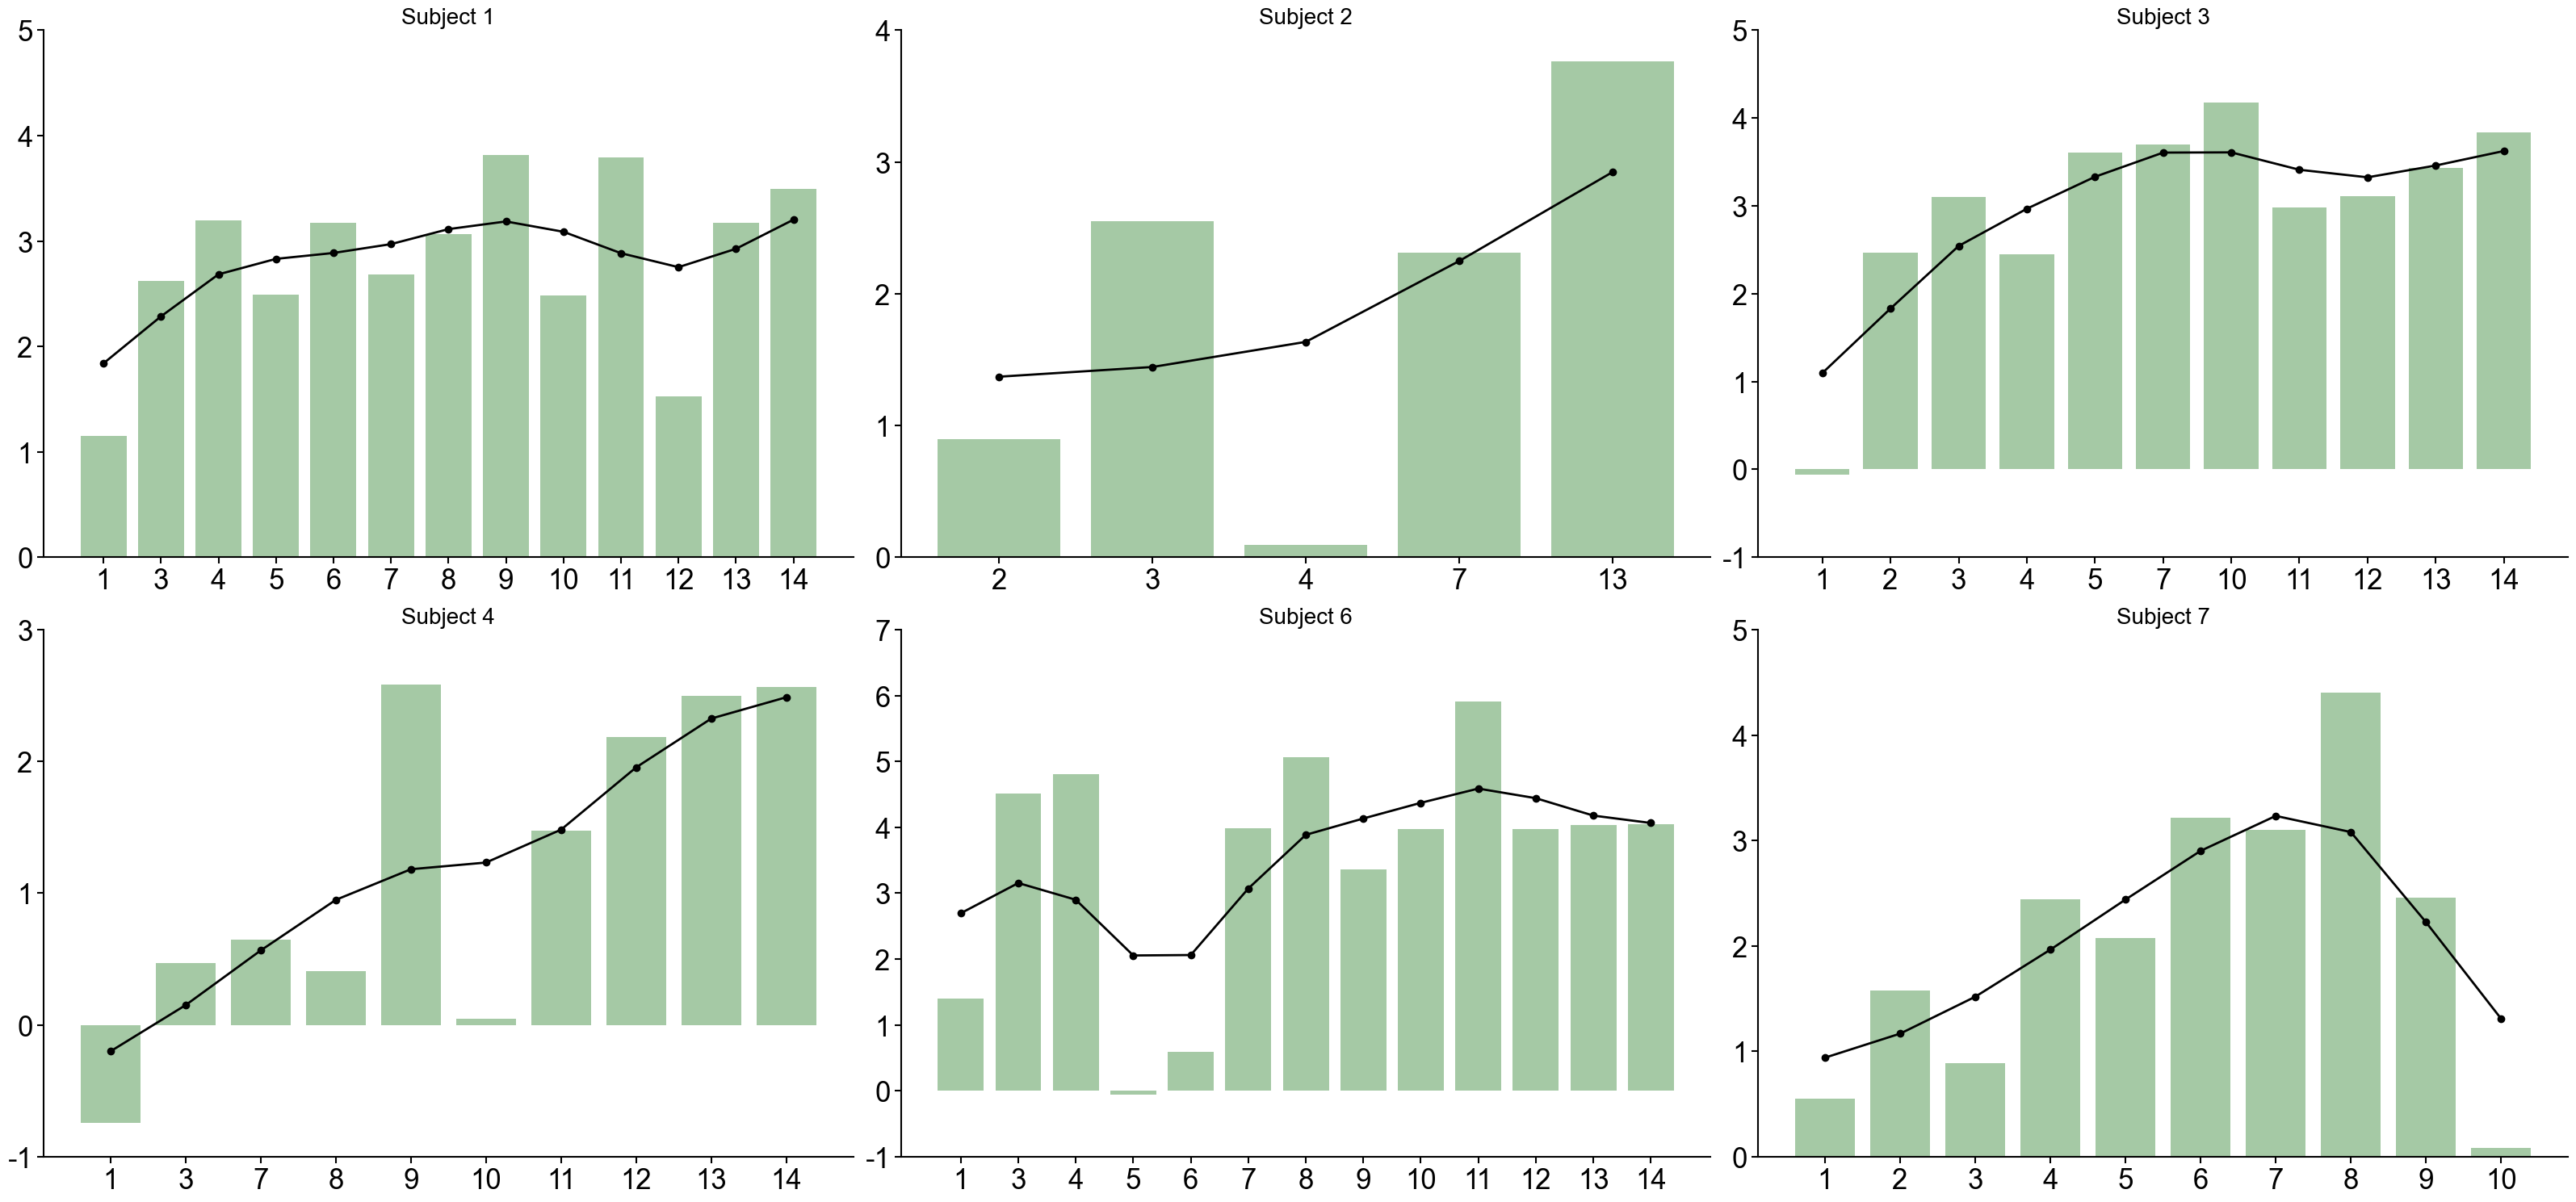

In [77]:
from functions_experimental_data_Bräckleinexp.decorrelation_time import *
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
import re
import pickle

def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)
    return int(match.group(1)) if match else 0

def plot_prolonged_firing_duration(directory_path, fsamp=2048,scatter_save_path=None, trend_save_path=None):
    
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day:
            files_by_day.setdefault(day, []).append(file)

    session_days = sorted(files_by_day.keys())
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]

    num_days = len(session_days)
    if num_days <= 20:
        color_map = {day: plt.cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}
    else:
        color_map = {day: plt.cm.viridis(i / num_days) for i, day in enumerate(session_days)}

    total_dur = []
    colors = []
    day_durations = {day: [] for day in session_days}

    for file_name in sorted_pkl_files:
        file_path = os.path.join(directory_path, file_name)
        with open(file_path, 'rb') as f:
            data = pickle.load(f)

        data_MU = np.array(data['MU'].tolist())
        idx_pair = data['Idx_MU_Pair'].tolist()

        spike_small = np.where(data_MU[idx_pair[0]] == 1)[0]
        spike_large = np.where(data_MU[idx_pair[1]] == 1)[0]

        if len(spike_small) == 0 or len(spike_large) == 0:
            continue

        duration = (spike_large[-1] - spike_small[-1]) / fsamp
        total_dur.append(duration)

        day = extract_day(file_name)
        colors.append(color_map[day])
        day_durations[day].append(duration)

    day_avg_durations = {day: np.mean(durations)for day, durations in day_durations.items() if durations}

    time = np.arange(len(total_dur))
    plt.figure(figsize=(10, 6))
    plt.scatter(time, total_dur, color=colors, alpha=0.8)
    plt.xlabel("File Index")
    plt.ylabel("Prolongated Firing Duration (s)")
    plt.title("Prolongated Firing Duration Across Sessions")

    for day, color in color_map.items():
        plt.scatter([], [], color=color, label=day)

    plt.legend(title="Session Day", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    if scatter_save_path:
        plt.savefig(scatter_save_path, dpi=300, bbox_inches='tight')
    plt.show()

    # Step 7: Bar plot with smoothed trend
    sorted_days = sorted(day_avg_durations.keys(), key=lambda x: int(re.search(r'\d+', x).group()))
    sorted_avg = [day_avg_durations[day] for day in sorted_days]
    smoothed_avg = gaussian_filter1d(sorted_avg, sigma=1.2)

    plt.figure(figsize=(12, 6))
    plt.bar(sorted_days, sorted_avg, color=[color_map[day] for day in sorted_days], alpha=0.6, label="Avg Duration")
    plt.plot(sorted_days, smoothed_avg, marker='o', linestyle='-', color='black', linewidth=2, label="Trend")

    plt.xlabel("Session Day")
    plt.ylabel("Average Prolongated Firing Duration (s)")
    plt.title("Average Prolongated Firing Duration Per Session (with Trend)")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    if trend_save_path:
        plt.savefig(trend_save_path, dpi=300, bbox_inches='tight')
    plt.show()

def plot_groupwise_prolonged_firing(session_files_dict, base_data_dir, fsamp=2048,save_path=None):
    """
    Plot average prolongated firing durations with smoothed trend across multiple subjects.

    Parameters:
    - session_files_dict: dict of dicts, e.g. {'S1': {'Day01': [...], 'Day02': [...]}, ...}
    - base_data_dir: str, path to the directory containing subject folders
    - fsamp: int, sampling frequency
    - save_path: str or None, if given, figure is saved there
    """
    fig, axes = plt.subplots(2, 3, figsize=(32, 15))
    axes = axes.flatten()

    for idx, (subject, subject_sessions) in enumerate(session_files_dict.items()):
        directory_path = os.path.join(base_data_dir, subject)
        day_durations = {day: [] for day in subject_sessions.keys()}

        for day, files in subject_sessions.items():
            for file_name in files:
                file_path = os.path.join(directory_path, file_name)
                with open(file_path, 'rb') as f:
                    data = pickle.load(f)

                data_MU = np.array(data['MU'].tolist())
                idx_pair = data['Idx_MU_Pair']

                spikes_small = np.where(data_MU[idx_pair[0]] == 1)[0]
                spikes_large = np.where(data_MU[idx_pair[1]] == 1)[0]

                if len(spikes_small) == 0 or len(spikes_large) == 0:
                    continue

                dur = (spikes_large[-1] - spikes_small[-1]) / fsamp
                day_durations[day].append(dur)

        # Compute averages
        day_avg_durations = {day: np.mean(durs) for day, durs in day_durations.items() if durs}
        sorted_days = sorted(day_avg_durations.keys(), key=lambda x: int(re.search(r'\d+', x).group()))
        sorted_avg_durations = [day_avg_durations[day] for day in sorted_days]
        smoothed_avg_durations = gaussian_filter1d(sorted_avg_durations, sigma=1.2)

        # Plotting
        ax = axes[idx]
        ax.bar(range(len(sorted_days)), sorted_avg_durations, color='#8FBC8F', alpha=0.8)
        ax.plot(range(len(sorted_days)), smoothed_avg_durations, marker='o',linestyle='-', color='black', linewidth=2)

        ax.set_title(f"Subject {subject[1]}", fontsize=20)
        day_numbers = [int(day[3:]) for day in sorted_days]
        ax.set_xticks(range(len(sorted_days)))
        ax.set_xticklabels(day_numbers, fontsize=25, rotation=0)
        ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=25)

        y_ticks = ax.get_yticks()
        y_ticks_int = [int(t) for t in y_ticks if np.isclose(t, round(t))]
        ax.set_yticks(y_ticks_int)
        ax.set_yticklabels([str(t) for t in y_ticks_int], fontsize=25)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        for spine in ['left', 'bottom']:
            ax.spines[spine].set_linewidth(1.5)

        ax.set_xlabel("")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()




plot_groupwise_prolonged_firing(session_files_dict={
        'S1': session_files1,
        'S2': session_files2,
        'S3': session_files3,
        'S4': session_files4,
        'S6': session_files6,
        'S7': session_files7
    },
    base_data_dir="/Users/nmt121/Desktop/DATA",
    fsamp=2048,
    # save_path="/Users/nmt121/Desktop/hysteresisdecorrtime.pdf"
)

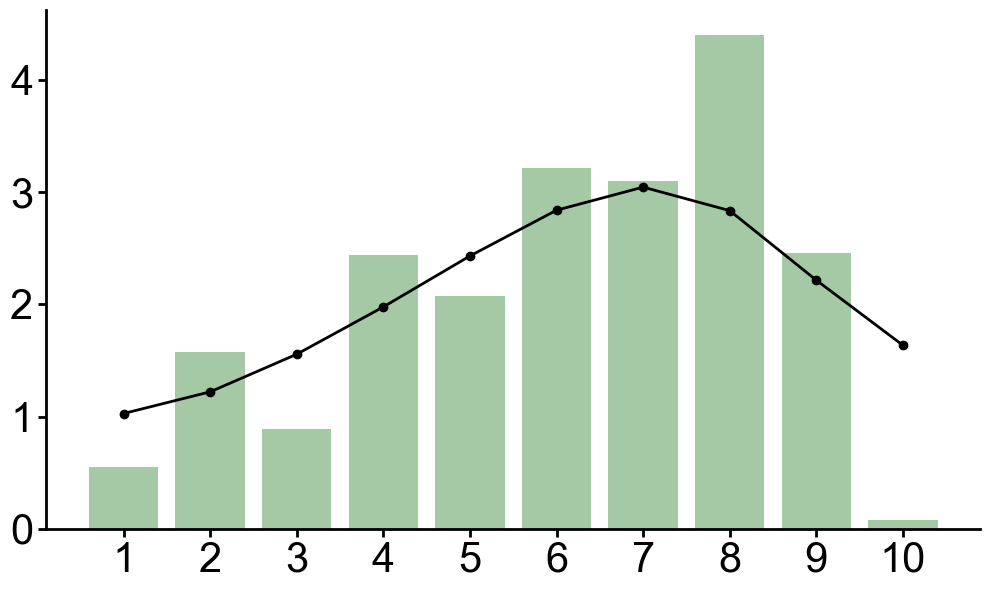

In [116]:
def plot_single_subject_prolonged_firing(subject_key, session_files_dict, base_data_dir, fsamp=2048, save_path=None):
    import matplotlib.pyplot as plt
    import numpy as np
    import os
    import pickle
    import re
    from scipy.ndimage import gaussian_filter1d

    # Set font
    plt.rcParams['font.family'] = 'Arial'

    session_files = session_files_dict[subject_key]
    directory_path = os.path.join(base_data_dir, subject_key)
    day_durations = {day: [] for day in session_files.keys()}

    # Extract durations
    for day, files in session_files.items():
        for file_name in files:
            file_path = os.path.join(directory_path, file_name)
            with open(file_path, 'rb') as f:
                data = pickle.load(f)

            data_MU = np.array(data['MU'].tolist())
            idx_pair = data['Idx_MU_Pair']

            spikes_small = np.where(data_MU[idx_pair[0]] == 1)[0]
            spikes_large = np.where(data_MU[idx_pair[1]] == 1)[0]

            if len(spikes_small) == 0 or len(spikes_large) == 0:
                continue

            dur = (spikes_large[-1] - spikes_small[-1]) / fsamp
            day_durations[day].append(dur)

    # Compute average per day
    day_avg_durations = {day: np.mean(durs) for day, durs in day_durations.items() if durs}
    sorted_days = sorted(day_avg_durations.keys(), key=lambda x: int(re.search(r'\d+', x).group()))
    x_labels = [int(day[3:]) for day in sorted_days]
    y_values = [day_avg_durations[day] for day in sorted_days]
    x_positions = np.arange(len(y_values))
    smoothed_values = gaussian_filter1d(y_values, sigma=1.5)

    # === Plotting ===
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.bar(x_positions, y_values, capsize=5, color='#8FBC8F', alpha=0.8)
    ax.plot(x_positions, smoothed_values, color='black', marker='o', linestyle='-', linewidth=2)

    ax.set_xticks(x_positions)
    ax.set_xticklabels(x_labels, fontsize=30)
    ax.tick_params(axis='both', which='major', width=2, length=6, labelsize=30)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(2)
    ax.spines['bottom'].set_linewidth(2)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

plot_single_subject_prolonged_firing(
    subject_key='S7',
    session_files_dict={
        'S1': session_files1,
        'S2': session_files2,
        'S3': session_files3,
        'S4': session_files4,
        'S6': session_files6,
        'S7': session_files7
    },
    base_data_dir="/Users/nmt121/Desktop/DATA",
    fsamp=2048,
    save_path="/Users/nmt121/Desktop/Figures/Decorrelation_times/Decorrelation_time_experimental7.pdf"
)


## FIRING RATES

In [ ]:
# Parameters
folder_path = "/Users/nmt121/Desktop/DATA/S1"  # Change to your folder path
fsamp = 2048  # Hz
window_duration = 0.3  # seconds

# Data structures: store max firing rates per neuron for each day
day_max_fr_0 = defaultdict(list)
day_max_fr_1 = defaultdict(list)

# List of pkl files
pkl_files = [f for f in os.listdir(folder_path) if f.endswith('.pkl')]

for file in pkl_files:
    file_path = os.path.join(folder_path, file)

    # Extract the "DayXX" part
    match = re.search(r'Day\d+', file)
    if match:
        day_id = match.group(0)
    else:
        continue

    # Load spike data
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_MU = np.array(data['MU'].tolist())
    idx_pair = data['Idx_MU_Pair'].tolist()

    # Create Hanning window
    window_samples = int(round(window_duration * fsamp))
    hanning_window = windows.hann(window_samples)
    hanning_window /= np.sum(hanning_window)

    # Smooth firing rates for the specific neurons
    smoothed_fr_0 = convolve(data_MU[idx_pair[0], :], hanning_window, mode='same') * fsamp
    smoothed_fr_1 = convolve(data_MU[idx_pair[1], :], hanning_window, mode='same') * fsamp

    # Compute max firing rates
    max_fr_0 = np.max(smoothed_fr_0)
    max_fr_1 = np.max(smoothed_fr_1)

    # Discard trials where either neuron’s firing rate exceeds 80 Hz
    if max_fr_0 > 80 or max_fr_1 > 80:
        continue

    # Store results
    day_max_fr_0[day_id].append(max_fr_0)
    day_max_fr_1[day_id].append(max_fr_1)


print('---')

# Compute and print average of the maximum firing rates for each day
for day_id in sorted(day_max_fr_0.keys()):
    if len(day_max_fr_0[day_id]) == 0:
        print(f'{day_id}: No valid trials below 80 Hz.')
        print('---')
        continue

    avg_max_fr_0 = np.mean(day_max_fr_0[day_id])
    avg_max_fr_1 = np.mean(day_max_fr_1[day_id])
    print(f'{day_id}:')
    print(f'  Average of max firing rates neuron 0: {avg_max_fr_0:.2f} Hz')
    print(f'  Average of max firing rates neuron 1: {avg_max_fr_1:.2f} Hz')
    print('---')


import csv
output_csv = os.path.join("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/max_fr_to_match", "average_max_firing_rates_per_day.csv")

# Write to CSV
with open(output_csv, mode='w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(['Day', 'Avg_Max_FR_Neuron_0', 'Avg_Max_FR_Neuron_1'])

    for day_id in sorted(day_max_fr_0.keys()):
        avg_max_fr_0 = np.mean(day_max_fr_0[day_id])
        avg_max_fr_1 = np.mean(day_max_fr_1[day_id])
        writer.writerow([day_id, f'{avg_max_fr_0:.4f}', f'{avg_max_fr_1:.4f}'])

print(f"Averages saved to {output_csv}")

---
Day01:
  Average of max firing rates neuron 0: 24.91 Hz
  Average of max firing rates neuron 1: 18.90 Hz
---
Day03:
  Average of max firing rates neuron 0: 23.22 Hz
  Average of max firing rates neuron 1: 24.75 Hz
---
Day04:
  Average of max firing rates neuron 0: 23.90 Hz
  Average of max firing rates neuron 1: 24.76 Hz
---
Day05:
  Average of max firing rates neuron 0: 14.30 Hz
  Average of max firing rates neuron 1: 15.50 Hz
---
Day06:
  Average of max firing rates neuron 0: 18.86 Hz
  Average of max firing rates neuron 1: 13.66 Hz
---
Day07:
  Average of max firing rates neuron 0: 31.16 Hz
  Average of max firing rates neuron 1: 38.36 Hz
---
Day08:
  Average of max firing rates neuron 0: 24.51 Hz
  Average of max firing rates neuron 1: 16.98 Hz
---
Day09:
  Average of max firing rates neuron 0: 20.10 Hz
  Average of max firing rates neuron 1: 19.92 Hz
---
Day10:
  Average of max firing rates neuron 0: 26.26 Hz
  Average of max firing rates neuron 1: 19.98 Hz
---
Day11:
  Averag

In [ ]:
import os
import re
import numpy as np
import h5py
from collections import defaultdict
from scipy.signal import convolve, windows

# === Parameters
fr_folder = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Spikes/Simulations_with_force_as_input/DR_S1"
vthca_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Subjects_optim_process/VthCa_TA_subject1_gamma1.jld2"
fsamp = 20000  # sampling rate in Hz
window_duration = 0.3  # seconds
tolerance_hz = 10.0

# === Function to compute smoothed firing rates
def compute_firing_rates(spike_array, fs, window_duration=0.3):
    window_samples = int(round(window_duration * fs))
    hanning_window = windows.hann(window_samples)
    hanning_window /= np.sum(hanning_window)

    smoothed_firing_rates = np.zeros_like(spike_array, dtype=float)
    for i in range(spike_array.shape[0]):
        smoothed_firing_rates[i, :] = convolve(spike_array[i, :], hanning_window, mode='same') * fs
    return smoothed_firing_rates

# === Load VthCa values
with h5py.File(vthca_path, 'r') as f:
    vthca = f['VthCa_newTA'][:]
    vth_values = vthca[:, 0]

# === Store valid pairs per day
valid_pairs_by_day = defaultdict(list)

# === Process each spike file
for filename in sorted(os.listdir(fr_folder)):
    if not filename.endswith(".jld2"):
        continue

    match = re.search(r'force(\d+)', filename)
    if not match:
        continue

    day_label = f'Day{int(match.group(1)):02d}'
    file_path = os.path.join(fr_folder, filename)

    with h5py.File(file_path, 'r') as f:
        spike_array = f['spike_array'][:]  # shape: (neurons, time), binary spikes

    # === Compute smoothed firing rates and max FR per neuron
    fr_matrix = compute_firing_rates(spike_array, fsamp)
    max_frs = np.max(fr_matrix, axis=1)

    # === Find valid neuron pairs
    n_neurons = 181
    for i in range(n_neurons - 1):
        for j in range(i + 1, n_neurons):
            vth_diff = vth_values[j] - vth_values[i]

            if vth_diff > 0:
                valid_pairs_by_day[day_label].append((i, j))

    print(f"{day_label}: Found {len(valid_pairs_by_day[day_label])} valid pairs")

# === Optional: Access results
# print(valid_pairs_by_day["Day05"])


In [ ]:
import pandas as pd

csv_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/max_fr_to_match/average_max_firing_rates_per_day.csv"
exp_df = pd.read_csv(csv_path)

# Example: get all day labels and experimental FRs
exp_by_day = {row['Day']: (float(row['Avg_Max_FR_Neuron_0']), float(row['Avg_Max_FR_Neuron_1']))for _, row in exp_df.iterrows()}


tolerance = 10.0
all_matches = {}  # day → list of (i, j) pairs

for day_label, (fr_target_0, fr_target_1) in exp_by_day.items():
    i_idx, j_idx = np.triu_indices(len(vth_values), k=1)
    vth_diff = vth_values[j_idx] - vth_values[i_idx]

    fr_i = max_frs[i_idx]
    fr_j = max_frs[j_idx]

    fr_match = (
        (np.abs(fr_i - fr_target_0) <= tolerance) &
        (np.abs(fr_j - fr_target_1) <= tolerance)
    )

    valid_mask = (vth_diff > 0) & fr_match
    matched_pairs = list(zip(i_idx[valid_mask], j_idx[valid_mask]))

    all_matches[day_label] = matched_pairs
    print(f"{day_label}: Found {len(matched_pairs)} matched pairs")


Day01: Found 0 matched pairs
Day03: Found 0 matched pairs
Day04: Found 0 matched pairs
Day05: Found 0 matched pairs
Day06: Found 0 matched pairs
Day07: Found 0 matched pairs
Day08: Found 0 matched pairs
Day09: Found 0 matched pairs
Day10: Found 0 matched pairs
Day11: Found 0 matched pairs
Day12: Found 0 matched pairs
Day13: Found 0 matched pairs
Day14: Found 0 matched pairs


In [27]:
# def plot_firing_rates(folder_path, pkl_files, fsamp=2048, window_duration=0.3, session_label=''):
#     num_files = len(pkl_files)      
#     cols = 3  # Number of columns for subplots
#     rows = math.ceil(num_files / cols)  # Compute number of rows

#     fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows), sharex=True, sharey=True)
#     axes = axes.flatten()

#     for idx, file in enumerate(pkl_files):
#         file_path = os.path.join(folder_path, file)

#         with open(file_path, 'rb') as f:
#             data = pickle.load(f)

#         data_MU = np.array(data['MU'].tolist())  
#         smoothed_firing_rates = compute_firing_rates(data_MU, fsamp, window_duration)
#         # idx_pair = data['Idx_MU_Pair'].tolist()

#         ax = axes[idx]
#         time_axis = np.arange(data_MU.shape[1]) / fsamp  # Convert sample index to time in seconds

#         for neuron_idx in range(data_MU.shape[0]):
#             if neuron_idx==idx_pair[1]:
#                 ax.plot(time_axis, smoothed_firing_rates[neuron_idx, :], label=f'Neuron {neuron_idx}', alpha=0.7)
#                 print(np.mean(smoothed_firing_rates[neuron_idx, :]))
                
#         num_neurons = data_MU.shape[0]  # Count the number of motoneurons
#         ax.set_title(f'{session_label} - Trial: {file}', fontsize=10)

#         ax.set_xlabel('Time (s)')
#         ax.set_ylabel('Firing Rate (Hz)')

#     # Remove unused subplots
#     for j in range(idx + 1, len(axes)):
#         fig.delaxes(axes[j])  

#     plt.tight_layout()
#     plt.ylim([0, 40])
#     plt.show()

# for session_name, file_list in session_files3.items():
#     folder_path = "/Users/nmt121/Desktop/DATA/S3"   # Adjust if needed
#     print(f"Plotting {session_name} with {len(file_list)} trials...")
    
#     plot_firing_rates(folder_path=folder_path,pkl_files=file_list,fsamp=2048,window_duration=0.3,session_label=session_name)
